In [1]:
%pip install torch torchvision timm scikit-learn matplotlib seaborn pandas numpy pillow tqdm grad-cam

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sys
import torch

print("Python:")
print(sys.executable)

print("\nPyTorch:")
print(torch.__version__)

print("\nCUDA:")
print(torch.version.cuda)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("\nGPU:")
    print(torch.cuda.get_device_name(0))

Python:
c:\Users\Apurv\Desktop\Dataset_29\.venv\Scripts\python.exe

PyTorch:
2.14.1+cu132

CUDA:
13.2

CUDA available:
True

GPU:
NVIDIA GeForce RTX 4050 Laptop GPU


In [3]:
import os
import copy
import math
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)

from sklearn.preprocessing import label_binarize

print("All libraries imported successfully!")

c:\Users\Apurv\Desktop\Dataset_29\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


In [4]:
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not available. "
        "Please install a CUDA-enabled PyTorch version."
    )

print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.14.1+cu132
CUDA version: 13.2
CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [5]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA GPU is not available. "
        "Please install a CUDA-enabled PyTorch version."
    )

DEVICE = torch.device("cuda")

print("\nGPU detected successfully!")
print("GPU:", torch.cuda.get_device_name(0))

gpu_properties = torch.cuda.get_device_properties(0)

print(
    "GPU Memory:",
    round(gpu_properties.total_memory / (1024 ** 3), 2),
    "GB"
)

torch.backends.cudnn.benchmark = True

PyTorch version: 2.14.1+cu132
CUDA version: 13.2
CUDA available: True

GPU detected successfully!
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
GPU Memory: 6.0 GB


In [6]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [7]:
PROJECT_DIR = Path.cwd()

DATASET_DIR = PROJECT_DIR / "Dataset_29"

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)

Project directory: c:\Users\Apurv\Desktop\Dataset_29
Dataset directory: c:\Users\Apurv\Desktop\Dataset_29\Dataset_29
Training directory: c:\Users\Apurv\Desktop\Dataset_29\Dataset_29\Training
Testing directory: c:\Users\Apurv\Desktop\Dataset_29\Dataset_29\Testing


In [8]:
# Block 5 — Dataset Paths

PROJECT_DIR = Path.cwd()

# The notebook is already inside Dataset_29
DATASET_DIR = PROJECT_DIR

TRAIN_DIR = DATASET_DIR / "Training"
TEST_DIR = DATASET_DIR / "Testing"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Training directory:", TRAIN_DIR)
print("Testing directory:", TEST_DIR)

Project directory: c:\Users\Apurv\Desktop\Dataset_29
Dataset directory: c:\Users\Apurv\Desktop\Dataset_29
Training directory: c:\Users\Apurv\Desktop\Dataset_29\Training
Testing directory: c:\Users\Apurv\Desktop\Dataset_29\Testing


In [9]:
# Verify Dataset

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATASET_DIR}"
    )

if not TRAIN_DIR.exists():
    raise FileNotFoundError(
        f"Training folder not found: {TRAIN_DIR}"
    )

if not TEST_DIR.exists():
    raise FileNotFoundError(
        f"Testing folder not found: {TEST_DIR}"
    )

print("Dataset paths verified successfully!")

Dataset paths verified successfully!


In [10]:
# Block 7 — Create Output Folders

OUTPUT_DIR = PROJECT_DIR / "outputs"

MODEL_DIR = OUTPUT_DIR / "models"
CM_DIR = OUTPUT_DIR / "confusion_matrices"
ROC_DIR = OUTPUT_DIR / "roc_curves"
PR_DIR = OUTPUT_DIR / "precision_recall"
TRAINING_CURVE_DIR = OUTPUT_DIR / "training_curves"
GRADCAM_DIR = OUTPUT_DIR / "gradcam"

for folder in [
    OUTPUT_DIR,
    MODEL_DIR,
    CM_DIR,
    ROC_DIR,
    PR_DIR,
    TRAINING_CURVE_DIR,
    GRADCAM_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Output folders created successfully!")

Output folders created successfully!


In [11]:
# Block 8 — Project Configuration

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

NUM_CLASSES = len(CLASS_NAMES)

IMAGE_SIZE = 224
BATCH_SIZE = 8

VALIDATION_SPLIT = 0.20

NUM_EPOCHS = 50
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

EARLY_STOPPING_PATIENCE = 4

NUM_WORKERS = 0

print("Classes:", CLASS_NAMES)
print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4
Image size: 224
Batch size: 8
Epochs: 50


In [12]:
# Block 9 — Training Transformations

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(10),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created.")

Training transformations created.


In [13]:
# Block 10 — Validation/Test Transformations

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation/Test transformations created.")

Validation/Test transformations created.


In [14]:
# Block 11 — Load Training Dataset

train_dataset_full = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

print("Training images:", len(train_dataset_full))
print("Classes:", train_dataset_full.classes)
print("Class mapping:", train_dataset_full.class_to_idx)

Training images: 5600
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


In [15]:
# Block 12 — Load Validation and Testing Dataset

# Same training images, but without augmentation.
# This copy will be used for validation.

train_dataset_eval = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=test_transform
)

# Separate testing dataset

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=test_transform
)

print("Validation source images:", len(train_dataset_eval))
print("Testing images:", len(test_dataset))

Validation source images: 5600
Testing images: 1600


In [16]:
# Block 13 — Verify Dataset Classes

expected_classes = sorted(CLASS_NAMES)

actual_train_classes = sorted(
    train_dataset_full.classes
)

actual_test_classes = sorted(
    test_dataset.classes
)

print("Expected classes:", expected_classes)
print("Training classes:", actual_train_classes)
print("Testing classes:", actual_test_classes)

if actual_train_classes != expected_classes:
    raise ValueError(
        "Training dataset classes do not match expected classes."
    )

if actual_test_classes != expected_classes:
    raise ValueError(
        "Testing dataset classes do not match expected classes."
    )

print("\nAll four classes verified successfully!")

Expected classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Testing classes: ['glioma', 'meningioma', 'notumor', 'pituitary']

All four classes verified successfully!


In [17]:
# Block 14 — Stratified Train/Validation Split

targets = np.array(
    train_dataset_full.targets
)

indices = np.arange(
    len(targets)
)

train_indices, val_indices = train_test_split(
    indices,
    test_size=VALIDATION_SPLIT,
    random_state=SEED,
    stratify=targets
)

train_dataset = Subset(
    train_dataset_full,
    train_indices
)

val_dataset = Subset(
    train_dataset_eval,
    val_indices
)

print("Total training source images:", len(targets))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Total training source images: 5600
Training images: 4480
Validation images: 1120


In [18]:
# Block 15 — Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 560
Validation batches: 140
Testing batches: 200


In [19]:
# Block 16 — Check Class Distribution

train_targets = targets[train_indices]
val_targets = targets[val_indices]
test_targets = np.array(
    test_dataset.targets
)

print("CLASS DISTRIBUTION")
print("=" * 55)

for class_index, class_name in enumerate(CLASS_NAMES):

    train_count = np.sum(
        train_targets == class_index
    )

    val_count = np.sum(
        val_targets == class_index
    )

    test_count = np.sum(
        test_targets == class_index
    )

    print(
        f"{class_name:12s} | "
        f"Train: {train_count:5d} | "
        f"Validation: {val_count:5d} | "
        f"Test: {test_count:5d}"
    )

CLASS DISTRIBUTION
glioma       | Train:  1120 | Validation:   280 | Test:   400
meningioma   | Train:  1120 | Validation:   280 | Test:   400
notumor      | Train:  1120 | Validation:   280 | Test:   400
pituitary    | Train:  1120 | Validation:   280 | Test:   400


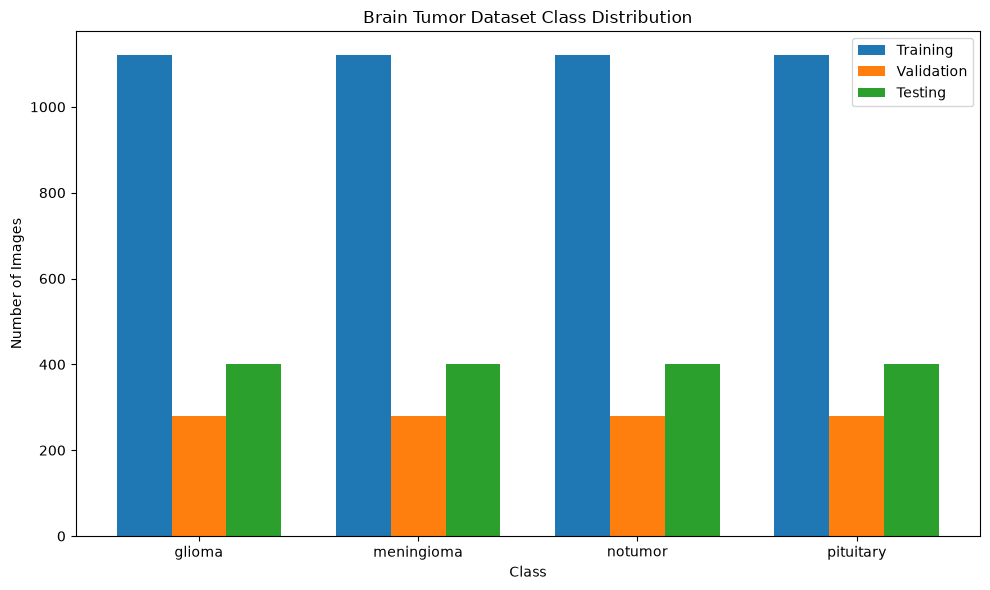

In [20]:
# Block 17 — Plot Class Distribution

train_counts = [
    np.sum(train_targets == i)
    for i in range(NUM_CLASSES)
]

val_counts = [
    np.sum(val_targets == i)
    for i in range(NUM_CLASSES)
]

test_counts = [
    np.sum(test_targets == i)
    for i in range(NUM_CLASSES)
]

x = np.arange(NUM_CLASSES)
width = 0.25

plt.figure(figsize=(10, 6))

plt.bar(
    x - width,
    train_counts,
    width,
    label="Training"
)

plt.bar(
    x,
    val_counts,
    width,
    label="Validation"
)

plt.bar(
    x + width,
    test_counts,
    width,
    label="Testing"
)

plt.xticks(x, CLASS_NAMES)

plt.xlabel("Class")
plt.ylabel("Number of Images")

plt.title("Brain Tumor Dataset Class Distribution")

plt.legend()
plt.tight_layout()

plt.show()

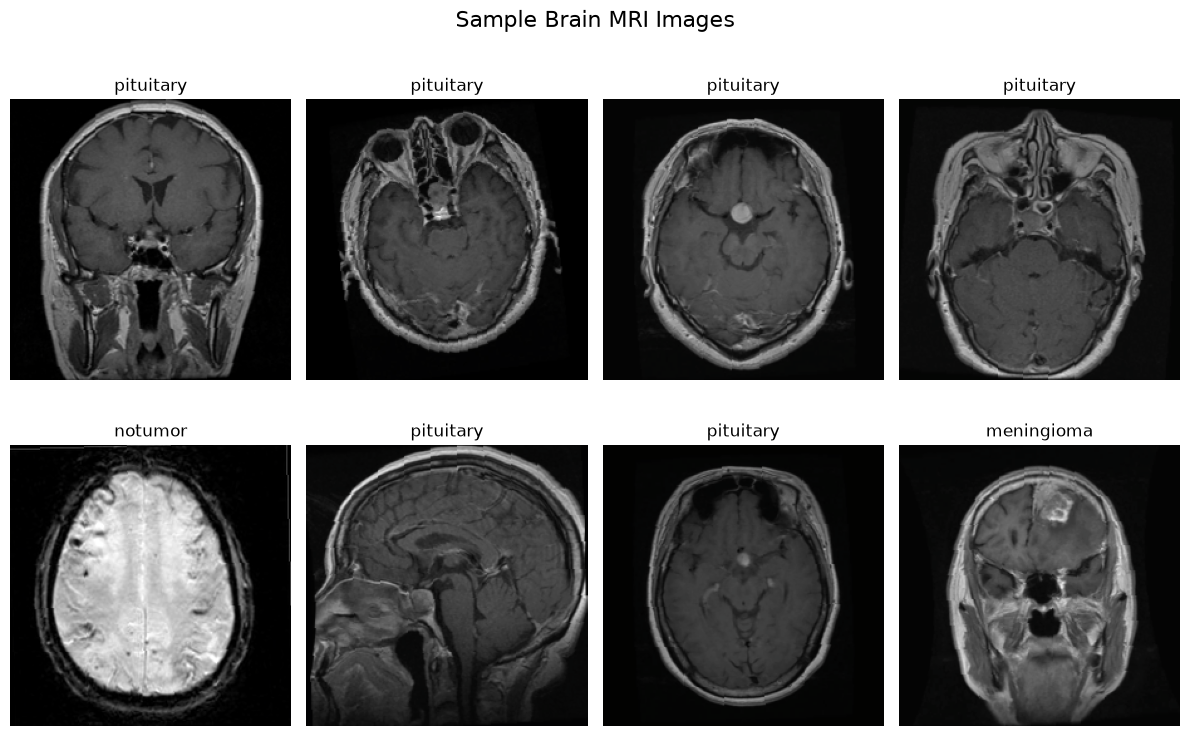

In [21]:
# Block 18 — Display Sample MRI Images

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(min(8, len(images))):

    image = images[i].permute(1, 2, 0).numpy()

    # Reverse ImageNet normalization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    plt.subplot(2, 4, i + 1)

    plt.imshow(image)

    plt.title(
        CLASS_NAMES[labels[i].item()]
    )

    plt.axis("off")

plt.suptitle(
    "Sample Brain MRI Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [22]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu132
CUDA: 13.2
CUDA Available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [23]:
# Block 19 — ResNet50

def create_resnet50(num_classes):

    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )

    # Replace original ImageNet classifier
    model.fc = nn.Linear(
        model.fc.in_features,
        num_classes
    )

    return model


print("ResNet50 function created successfully.")

ResNet50 function created successfully.


In [24]:
# Block 20 — MobileViT

def create_mobilevit(num_classes):

    model = timm.create_model(
        "mobilevit_xs",
        pretrained=True,
        num_classes=num_classes
    )

    return model


print("MobileViT function created successfully.")

MobileViT function created successfully.


In [25]:
# Block 21 — Vision Transformer

def create_vit(num_classes):

    model = timm.create_model(
        "vit_base_patch16_224",
        pretrained=True,
        num_classes=num_classes
    )

    return model


print("ViT function created successfully.")

ViT function created successfully.


In [26]:
# Block 22 — Swin Transformer

def create_swin(num_classes):

    model = timm.create_model(
        "swin_tiny_patch4_window7_224",
        pretrained=True,
        num_classes=num_classes
    )

    return model


print("Swin Transformer function created successfully.")

Swin Transformer function created successfully.


In [27]:
# Block 23 — Model Dictionary

MODEL_CREATORS = {

    "ResNet50": create_resnet50,

    "MobileViT": create_mobilevit,

    "ViT": create_vit,

    "SwinTransformer": create_swin
}

print("Models configured successfully:\n")

for model_name in MODEL_CREATORS:
    print("-", model_name)

Models configured successfully:

- ResNet50
- MobileViT
- ViT
- SwinTransformer


In [28]:
# Block 24 — Test ResNet50

resnet50_model = create_resnet50(NUM_CLASSES)

resnet50_model = resnet50_model.to(DEVICE)

print("ResNet50 created successfully.")
print("Device:", DEVICE)

ResNet50 created successfully.
Device: cuda


In [29]:
# Block 25 — ResNet50 Forward Pass Test

images, labels = next(iter(train_loader))

images = images.to(
    DEVICE,
    non_blocking=True
)

with torch.no_grad():

    outputs = resnet50_model(images)

print("Input shape :", images.shape)
print("Output shape:", outputs.shape)

Input shape : torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 4])


In [30]:
# Block 26 — Clear ResNet50 Test Model

del resnet50_model

torch.cuda.empty_cache()

gc.collect()

print("GPU memory cleared.")

GPU memory cleared.


In [31]:
# Block 27 — Loss Function and Training Settings

criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)
print("Learning rate:", LEARNING_RATE)
print("Weight decay:", WEIGHT_DECAY)
print("Early stopping patience:", EARLY_STOPPING_PATIENCE)

Loss function: CrossEntropyLoss()
Learning rate: 0.0001
Weight decay: 0.0001
Early stopping patience: 4


In [32]:
# Block 28 — Optimizer and Learning Rate Scheduler

def create_optimizer(model):

    optimizer = optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    return optimizer, scheduler


print("Optimizer and scheduler function created.")

Optimizer and scheduler function created.


In [33]:
# Block 29 — Mixed Precision Training

scaler = torch.amp.GradScaler("cuda")

print("CUDA mixed-precision scaler initialized.")

CUDA mixed-precision scaler initialized.


In [34]:
# Block 30 — Training Epoch Function

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress_bar:

        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total += labels.size(0)

        progress_bar.set_postfix(
            loss=loss.item()
        )

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [35]:
# Block 31 — Validation Function

def validate_one_epoch(
    model,
    loader,
    criterion
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for images, labels in progress_bar:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            labels = labels.to(
                DEVICE,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [36]:
def train_model(
    model,
    model_name,
    num_epochs=NUM_EPOCHS,
    early_stopping=True
):

    model = model.to(DEVICE)

    optimizer, scheduler = create_optimizer(
        model
    )

    best_val_loss = float("inf")
    best_model_state = None

    patience_counter = 0

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    print("\n" + "=" * 60)
    print(f"Training {model_name}")
    print("=" * 60)

    for epoch in range(num_epochs):

        print(
            f"\nEpoch {epoch + 1}/{num_epochs}"
        )

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            scaler
        )

        val_loss, val_accuracy = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        scheduler.step(val_loss)

        history["train_loss"].append(
            train_loss
        )

        history["train_accuracy"].append(
            train_accuracy
        )

        history["val_loss"].append(
            val_loss
        )

        history["val_accuracy"].append(
            val_accuracy
        )

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f}"
        )

        print(
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.4f}"
        )

        print(
            f"Learning Rate: {current_lr:.2e}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_model_state = copy.deepcopy(
                model.state_dict()
            )

            patience_counter = 0

            print("✓ Best model updated.")

        else:

            patience_counter += 1

            print(
                f"No improvement. "
                f"Patience: {patience_counter}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )

        # Early stopping only when enabled
        if (
            early_stopping
            and patience_counter >= EARLY_STOPPING_PATIENCE
        ):

            print("\nEarly stopping triggered.")

            break

    if best_model_state is not None:

        model.load_state_dict(
            best_model_state
        )

    print(
        f"\nBest validation loss: "
        f"{best_val_loss:.4f}"
    )

    return model, history

In [37]:
# Block 33 — Save Model

def save_model(
    model,
    model_name
):

    model_path = MODEL_DIR / f"{model_name}.pth"

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "model_name": model_name,
            "class_names": CLASS_NAMES,
            "num_classes": NUM_CLASSES,
            "image_size": IMAGE_SIZE
        },
        model_path
    )

    print(
        f"Model saved successfully:\n{model_path}"
    )

    return model_path

In [38]:
# Block 34 — Training Curves Function

def plot_training_curves(
    history,
    model_name
):

    epochs = range(
        1,
        len(history["train_loss"]) + 1
    )

    # Loss curve
    plt.figure(figsize=(8, 6))

    plt.plot(
        epochs,
        history["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"{model_name} - Loss Curve"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    loss_path = (
        TRAINING_CURVE_DIR
        / f"{model_name}_loss.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # Accuracy curve
    plt.figure(figsize=(8, 6))

    plt.plot(
        epochs,
        history["train_accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"{model_name} - Accuracy Curve"
    )

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()

    accuracy_path = (
        TRAINING_CURVE_DIR
        / f"{model_name}_accuracy.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Training curves saved for {model_name}."
    )

In [39]:
# Block 35 — Create ResNet50 for Training

model = create_resnet50(NUM_CLASSES)

model = model.to(DEVICE)

print("ResNet50 ready for training.")
print("Device:", DEVICE)

ResNet50 ready for training.
Device: cuda


In [40]:
# Block 36 — Train ResNet50

resnet50_model, resnet50_history = train_model(
    model=model,
    model_name="ResNet50"
)

print("\nResNet50 training completed!")


Training ResNet50

Epoch 1/50


Train Loss: 0.4074 | Train Acc: 0.8560
Val Loss: nan | Val Acc: 0.9670
Learning Rate: 1.00e-04
No improvement. Patience: 1/4

Epoch 2/50


Train Loss: 0.1547 | Train Acc: 0.9496
Val Loss: 0.0747 | Val Acc: 0.9705
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 3/50


Train Loss: 0.0914 | Train Acc: 0.9674
Val Loss: 0.0837 | Val Acc: 0.9759
Learning Rate: 1.00e-04
No improvement. Patience: 1/4

Epoch 4/50


Train Loss: 0.0675 | Train Acc: 0.9775
Val Loss: 0.0483 | Val Acc: 0.9866
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 5/50


Train Loss: 0.0611 | Train Acc: 0.9804
Val Loss: 0.0399 | Val Acc: 0.9857
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 6/50


... (6 outputs left out)

Train Loss: 0.0151 | Train Acc: 0.9951
Val Loss: 0.0353 | Val Acc: 0.9902
Learning Rate: 5.00e-05
No improvement. Patience: 1/4

Epoch 13/50


Train Loss: 0.0110 | Train Acc: 0.9969
Val Loss: 0.0360 | Val Acc: 0.9911
Learning Rate: 5.00e-05
No improvement. Patience: 2/4

Epoch 14/50


Train Loss: 0.0115 | Train Acc: 0.9964
Val Loss: 0.0345 | Val Acc: 0.9866
Learning Rate: 2.50e-05
No improvement. Patience: 3/4

Epoch 15/50


Train Loss: 0.0077 | Train Acc: 0.9967
Val Loss: 0.0354 | Val Acc: 0.9893
Learning Rate: 2.50e-05
No improvement. Patience: 4/4

Early stopping triggered.

Best validation loss: 0.0265

ResNet50 training completed!


In [41]:
# Block 37 — Save ResNet50

resnet50_path = save_model(
    resnet50_model,
    "ResNet50"
)

print("ResNet50 checkpoint saved at:")
print(resnet50_path)

Model saved successfully:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ResNet50.pth
ResNet50 checkpoint saved at:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ResNet50.pth


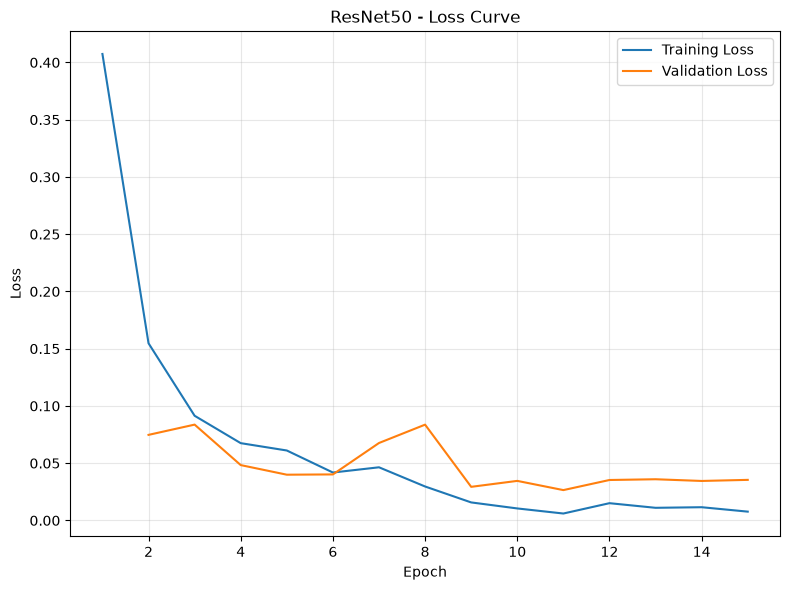

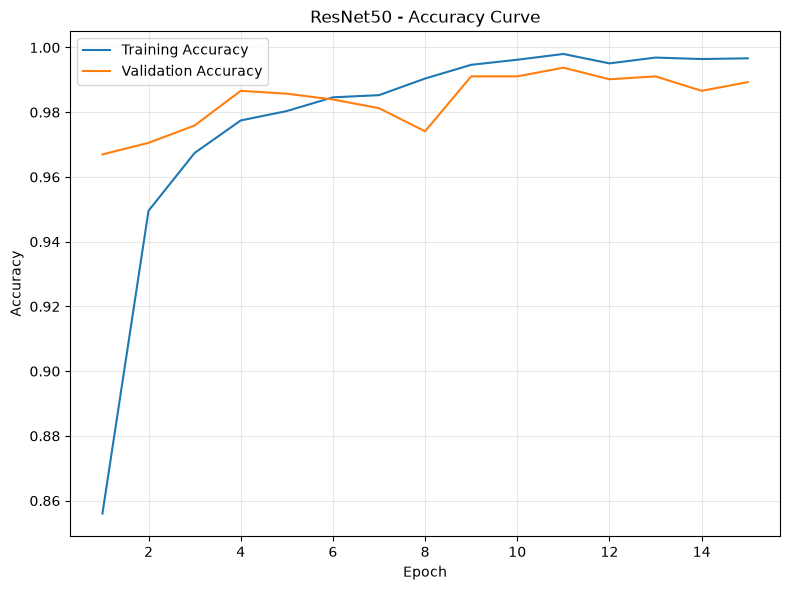

Training curves saved for ResNet50.


In [42]:
# Block 38 — ResNet50 Training Curves

plot_training_curves(
    resnet50_history,
    "ResNet50"
)

In [43]:
# Block 39 — Free ResNet50 GPU Memory

del resnet50_model
del model

torch.cuda.empty_cache()
gc.collect()

print("ResNet50 removed from GPU memory.")

ResNet50 removed from GPU memory.


In [44]:
# Block 40 — Create MobileViT

model = create_mobilevit(NUM_CLASSES)

model = model.to(DEVICE)

print("MobileViT ready for training.")
print("Device:", DEVICE)

MobileViT ready for training.
Device: cuda


In [45]:
# Block 41 — Train MobileViT

mobilevit_model, mobilevit_history = train_model(
    model=model,
    model_name="MobileViT"
)

print("\nMobileViT training completed!")


Training MobileViT

Epoch 1/50


Train Loss: 0.6759 | Train Acc: 0.8114
Val Loss: 0.2375 | Val Acc: 0.9170
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 2/50


Train Loss: 0.3341 | Train Acc: 0.9016
Val Loss: 0.1256 | Val Acc: 0.9634
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 3/50


Train Loss: 0.2149 | Train Acc: 0.9393
Val Loss: 0.1099 | Val Acc: 0.9652
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 4/50


Train Loss: 0.1550 | Train Acc: 0.9522
Val Loss: 0.1534 | Val Acc: 0.9330
Learning Rate: 1.00e-04
No improvement. Patience: 1/4

Epoch 5/50


Train Loss: 0.1153 | Train Acc: 0.9696
Val Loss: 0.0779 | Val Acc: 0.9714
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 6/50


... (10 outputs left out)

Train Loss: 0.0119 | Train Acc: 0.9969
Val Loss: 0.0308 | Val Acc: 0.9893
Learning Rate: 2.50e-05
No improvement. Patience: 1/4

Epoch 17/50


Train Loss: 0.0108 | Train Acc: 0.9978
Val Loss: 0.0249 | Val Acc: 0.9920
Learning Rate: 2.50e-05
No improvement. Patience: 2/4

Epoch 18/50


Train Loss: 0.0108 | Train Acc: 0.9978
Val Loss: 0.0414 | Val Acc: 0.9911
Learning Rate: 1.25e-05
No improvement. Patience: 3/4

Epoch 19/50


Train Loss: 0.0095 | Train Acc: 0.9973
Val Loss: 0.0329 | Val Acc: 0.9911
Learning Rate: 1.25e-05
No improvement. Patience: 4/4

Early stopping triggered.

Best validation loss: 0.0218

MobileViT training completed!


In [46]:
# Block 42 — Save MobileViT

mobilevit_path = save_model(
    mobilevit_model,
    "MobileViT"
)

print("MobileViT checkpoint saved at:")
print(mobilevit_path)

Model saved successfully:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\MobileViT.pth
MobileViT checkpoint saved at:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\MobileViT.pth


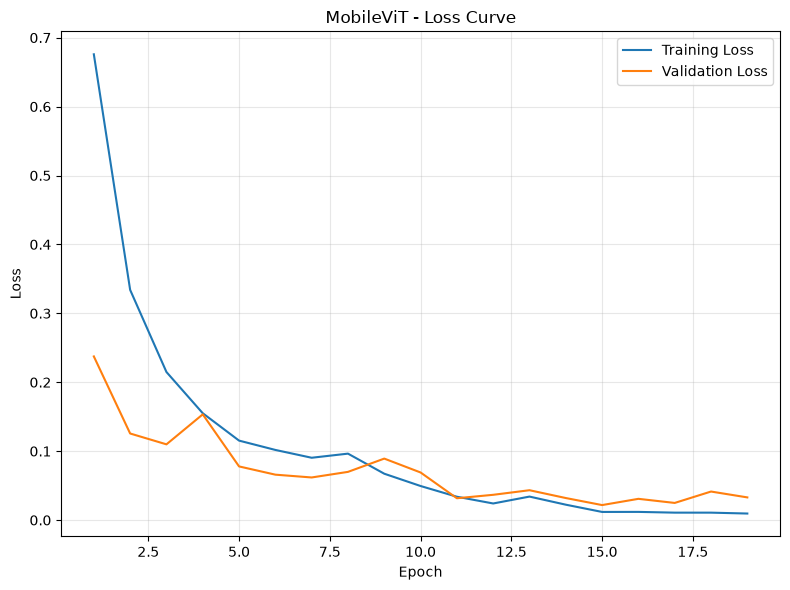

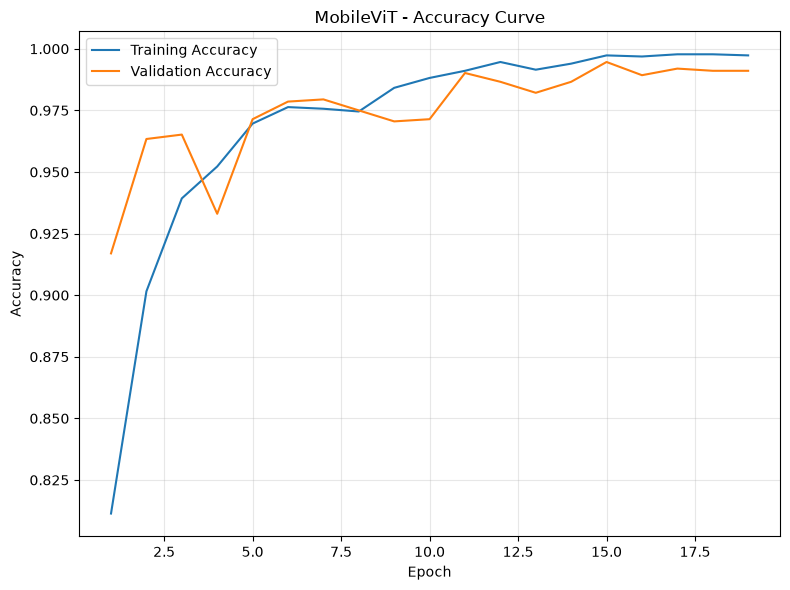

Training curves saved for MobileViT.


In [47]:
# Block 43 — MobileViT Training Curves

plot_training_curves(
    mobilevit_history,
    "MobileViT"
)

In [48]:
# Block 44 — Free MobileViT GPU Memory

del mobilevit_model
del model

torch.cuda.empty_cache()
gc.collect()

print("MobileViT removed from GPU memory.")

MobileViT removed from GPU memory.


In [49]:
# Block 45 — Create Vision Transformer

model = create_vit(NUM_CLASSES)

model = model.to(DEVICE)

print("Vision Transformer ready for training.")
print("Device:", DEVICE)

Vision Transformer ready for training.
Device: cuda


In [50]:
# Block 46 — Train Vision Transformer

vit_model, vit_history = train_model(
    model=model,
    model_name="ViT"
)

print("\nVision Transformer training completed!")


Training ViT

Epoch 1/50


Train Loss: 0.7417 | Train Acc: 0.7047
Val Loss: 0.3450 | Val Acc: 0.8696
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 2/50


Train Loss: 0.3146 | Train Acc: 0.8848
Val Loss: 0.2237 | Val Acc: 0.9161
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 3/50


Train Loss: 0.2232 | Train Acc: 0.9167
Val Loss: 0.1775 | Val Acc: 0.9321
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 4/50


Train Loss: 0.1981 | Train Acc: 0.9277
Val Loss: 0.3236 | Val Acc: 0.8821
Learning Rate: 1.00e-04
No improvement. Patience: 1/4

Epoch 5/50


Train Loss: 0.1795 | Train Acc: 0.9346
Val Loss: 0.1347 | Val Acc: 0.9491
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 6/50


... (8 outputs left out)

Train Loss: 0.0393 | Train Acc: 0.9879
Val Loss: 0.0820 | Val Acc: 0.9750
Learning Rate: 5.00e-05
No improvement. Patience: 1/4

Epoch 15/50


Train Loss: 0.0474 | Train Acc: 0.9837
Val Loss: 0.0676 | Val Acc: 0.9804
Learning Rate: 5.00e-05
No improvement. Patience: 2/4

Epoch 16/50


Train Loss: 0.0404 | Train Acc: 0.9844
Val Loss: 0.0778 | Val Acc: 0.9750
Learning Rate: 2.50e-05
No improvement. Patience: 3/4

Epoch 17/50


Train Loss: 0.0163 | Train Acc: 0.9946
Val Loss: 0.0593 | Val Acc: 0.9795
Learning Rate: 2.50e-05
No improvement. Patience: 4/4

Early stopping triggered.

Best validation loss: 0.0557

Vision Transformer training completed!


In [51]:
vit_path = save_model(
    vit_model,
    "ViT"
)

print("ViT checkpoint saved at:")
print(vit_path)

Model saved successfully:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ViT.pth
ViT checkpoint saved at:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ViT.pth


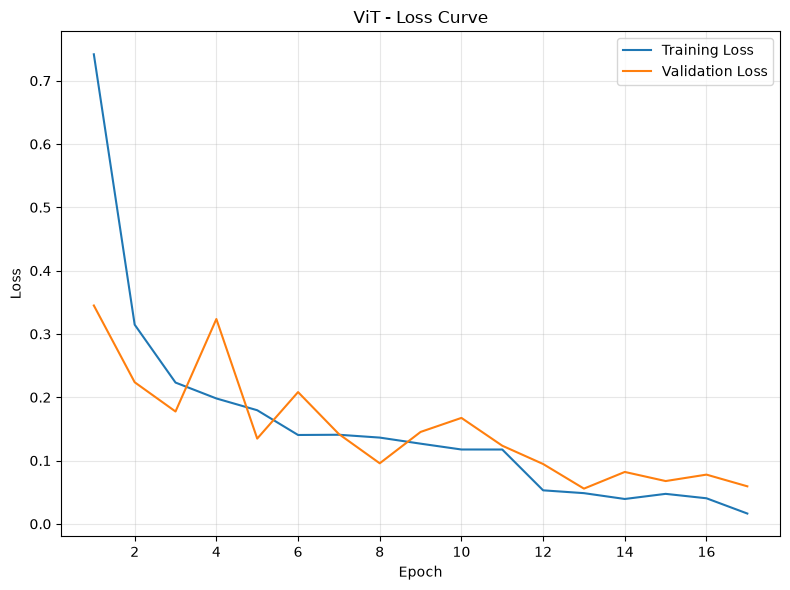

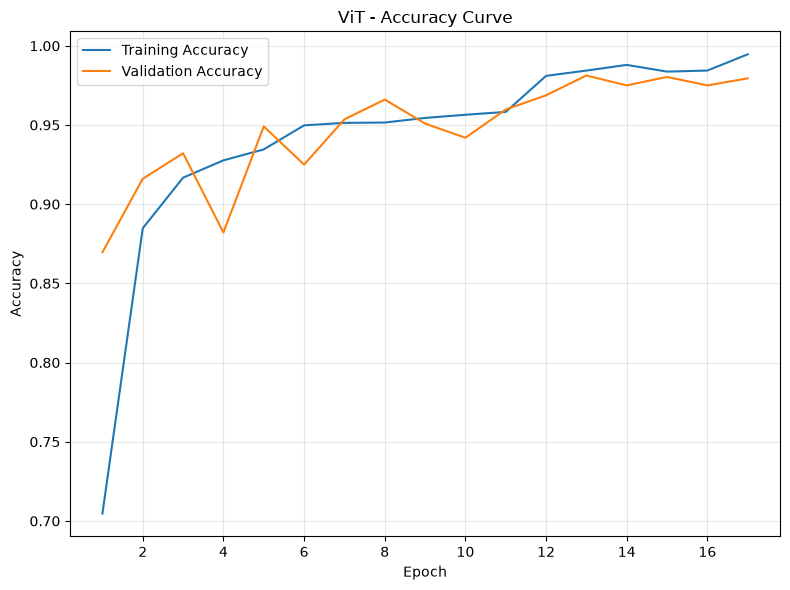

Training curves saved for ViT.


In [52]:
plot_training_curves(
    vit_history,
    "ViT"
)

In [53]:
del vit_model
del model

torch.cuda.empty_cache()
gc.collect()

print("ViT removed from GPU memory.")

ViT removed from GPU memory.


In [54]:
model = create_swin(NUM_CLASSES)

model = model.to(DEVICE)

print("Swin Transformer ready for training.")
print("Device:", DEVICE)

Swin Transformer ready for training.
Device: cuda


In [55]:
swin_model, swin_history = train_model(
    model=model,
    model_name="SwinTransformer",
    early_stopping=True
)

print("\nSwin Transformer training completed!")


Training SwinTransformer

Epoch 1/50


Train Loss: 0.3265 | Train Acc: 0.8824
Val Loss: 0.2564 | Val Acc: 0.9000
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 2/50


Train Loss: 0.1493 | Train Acc: 0.9531
Val Loss: 0.0895 | Val Acc: 0.9741
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 3/50


Train Loss: 0.1213 | Train Acc: 0.9636
Val Loss: 0.0671 | Val Acc: 0.9777
Learning Rate: 1.00e-04
✓ Best model updated.

Epoch 4/50


Train Loss: 0.0966 | Train Acc: 0.9650
Val Loss: 0.0752 | Val Acc: 0.9777
Learning Rate: 1.00e-04
No improvement. Patience: 1/4

Epoch 5/50


Train Loss: 0.0697 | Train Acc: 0.9788
Val Loss: 0.0914 | Val Acc: 0.9705
Learning Rate: 1.00e-04
No improvement. Patience: 2/4

Epoch 6/50


... (5 outputs left out)

Train Loss: 0.0134 | Train Acc: 0.9953
Val Loss: 0.0925 | Val Acc: 0.9732
Learning Rate: 5.00e-05
No improvement. Patience: 1/4

Epoch 12/50


Train Loss: 0.0343 | Train Acc: 0.9893
Val Loss: 0.0911 | Val Acc: 0.9741
Learning Rate: 5.00e-05
No improvement. Patience: 2/4

Epoch 13/50


Train Loss: 0.0175 | Train Acc: 0.9935
Val Loss: 0.0594 | Val Acc: 0.9795
Learning Rate: 2.50e-05
No improvement. Patience: 3/4

Epoch 14/50


Train Loss: 0.0077 | Train Acc: 0.9980
Val Loss: 0.0442 | Val Acc: 0.9884
Learning Rate: 2.50e-05
No improvement. Patience: 4/4

Early stopping triggered.

Best validation loss: 0.0299

Swin Transformer training completed!


In [56]:
swin_path = save_model(
    swin_model,
    "SwinTransformer"
)

print("Swin Transformer checkpoint saved at:")
print(swin_path)

Model saved successfully:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\SwinTransformer.pth
Swin Transformer checkpoint saved at:
c:\Users\Apurv\Desktop\Dataset_29\outputs\models\SwinTransformer.pth


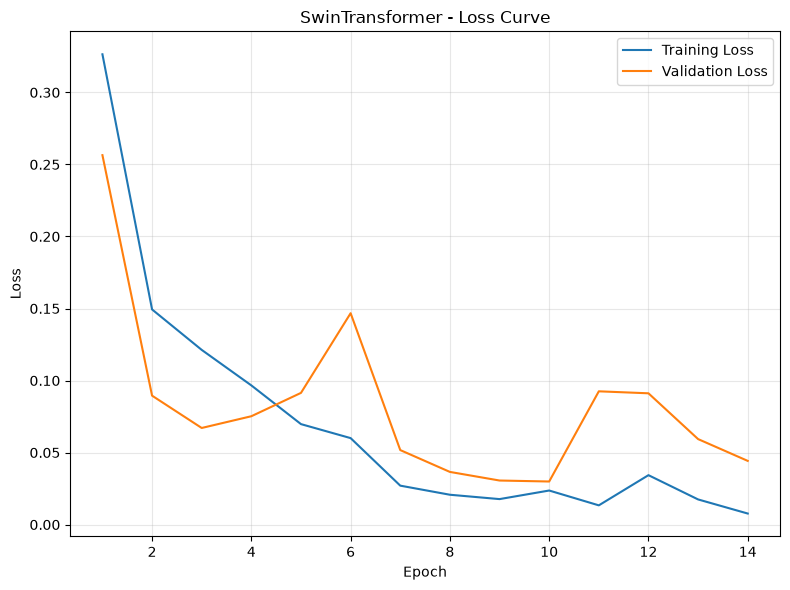

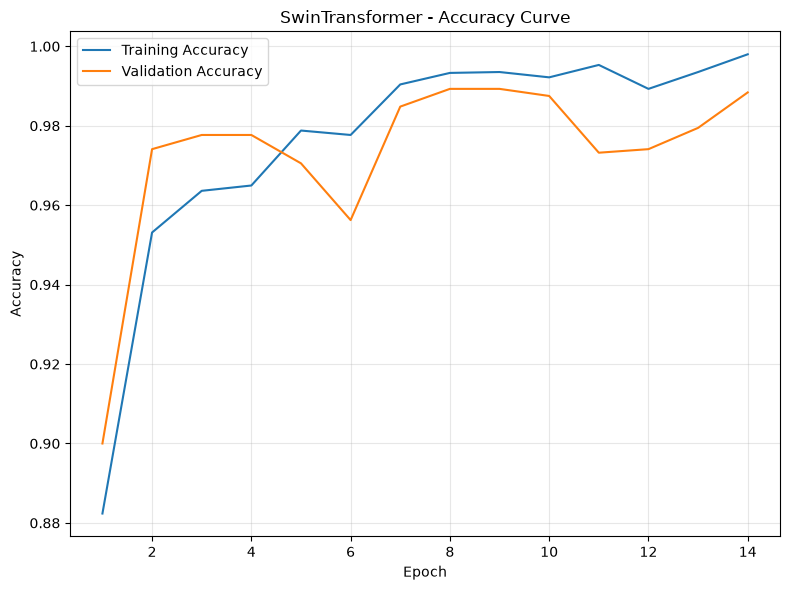

Training curves saved for SwinTransformer.


In [57]:
plot_training_curves(
    swin_history,
    "SwinTransformer"
)

In [58]:
del swin_model
del model

torch.cuda.empty_cache()
gc.collect()

print("Swin Transformer removed from GPU memory.")

Swin Transformer removed from GPU memory.


In [59]:
def get_predictions(
    model,
    loader
):

    model.eval()

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        progress_bar = tqdm(
            loader,
            desc="Evaluating",
            leave=False
        )

        for images, labels in progress_bar:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predictions = torch.argmax(
                probabilities,
                dim=1
            )

            all_labels.extend(
                labels.numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.concatenate(
            all_probabilities,
            axis=0
        )
    )

print("Prediction function created successfully.")

Prediction function created successfully.


In [60]:
from sklearn.metrics import roc_auc_score


def calculate_metrics(
    y_true,
    y_pred,
    y_prob
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    roc_auc = roc_auc_score(
        y_true_binary,
        y_prob,
        average="macro",
        multi_class="ovr"
    )

    pr_auc = average_precision_score(
        y_true_binary,
        y_prob,
        average="macro"
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC AUC": roc_auc,
        "PR AUC": pr_auc
    }

In [61]:
def evaluate_model(
    model,
    model_name
):

    model = model.to(DEVICE)

    y_true, y_pred, y_prob = get_predictions(
        model,
        test_loader
    )

    metrics = calculate_metrics(
        y_true,
        y_pred,
        y_prob
    )

    print("\n" + "=" * 60)
    print(f"{model_name} - TEST RESULTS")
    print("=" * 60)

    for metric_name, value in metrics.items():

        print(
            f"{metric_name:12s}: "
            f"{value:.4f}"
        )

    return (
        metrics,
        y_true,
        y_pred,
        y_prob
    )

print("Model evaluation function created successfully.")

Model evaluation function created successfully.


In [62]:
resnet50_model = create_resnet50(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "ResNet50.pth",
    map_location=DEVICE
)

resnet50_model.load_state_dict(
    checkpoint["model_state_dict"]
)

(
    resnet50_metrics,
    resnet50_y_true,
    resnet50_y_pred,
    resnet50_y_prob
) = evaluate_model(
    resnet50_model,
    "ResNet50"
)


ResNet50 - TEST RESULTS
Accuracy    : 0.9519
Precision   : 0.9550
Recall      : 0.9519
F1 Score    : 0.9508
ROC AUC     : 0.9897
PR AUC      : 0.9754


In [63]:
del resnet50_model
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print("ResNet50 evaluation completed.")
print("GPU memory cleared.")

ResNet50 evaluation completed.
GPU memory cleared.


In [64]:
mobilevit_model = create_mobilevit(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "MobileViT.pth",
    map_location=DEVICE
)

mobilevit_model.load_state_dict(
    checkpoint["model_state_dict"]
)

(
    mobilevit_metrics,
    mobilevit_y_true,
    mobilevit_y_pred,
    mobilevit_y_prob
) = evaluate_model(
    mobilevit_model,
    "MobileViT"
)


MobileViT - TEST RESULTS
Accuracy    : 0.9550
Precision   : 0.9583
Recall      : 0.9550
F1 Score    : 0.9541
ROC AUC     : 0.9926
PR AUC      : 0.9779


In [65]:
del mobilevit_model
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print("MobileViT evaluation completed.")
print("GPU memory cleared.")

MobileViT evaluation completed.
GPU memory cleared.


In [66]:
vit_model = create_vit(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "ViT.pth",
    map_location=DEVICE
)

vit_model.load_state_dict(
    checkpoint["model_state_dict"]
)

(
    vit_metrics,
    vit_y_true,
    vit_y_pred,
    vit_y_prob
) = evaluate_model(
    vit_model,
    "ViT"
)


ViT - TEST RESULTS
Accuracy    : 0.9313
Precision   : 0.9350
Recall      : 0.9313
F1 Score    : 0.9293
ROC AUC     : 0.9882
PR AUC      : 0.9738


In [67]:
del vit_model
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print("ViT evaluation completed.")
print("GPU memory cleared.")

ViT evaluation completed.
GPU memory cleared.


In [68]:
swin_model = create_swin(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "SwinTransformer.pth",
    map_location=DEVICE
)

swin_model.load_state_dict(
    checkpoint["model_state_dict"]
)

(
    swin_metrics,
    swin_y_true,
    swin_y_pred,
    swin_y_prob
) = evaluate_model(
    swin_model,
    "SwinTransformer"
)


SwinTransformer - TEST RESULTS
Accuracy    : 0.9556
Precision   : 0.9587
Recall      : 0.9556
F1 Score    : 0.9546
ROC AUC     : 0.9870
PR AUC      : 0.9746


In [69]:
del swin_model
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print("Swin Transformer evaluation completed.")
print("GPU memory cleared.")

Swin Transformer evaluation completed.
GPU memory cleared.


In [70]:
model_comparison = pd.DataFrame({

    "Model": [
        "ResNet50",
        "MobileViT",
        "ViT",
        "SwinTransformer"
    ],

    "Accuracy": [
        resnet50_metrics["Accuracy"],
        mobilevit_metrics["Accuracy"],
        vit_metrics["Accuracy"],
        swin_metrics["Accuracy"]
    ],

    "Precision": [
        resnet50_metrics["Precision"],
        mobilevit_metrics["Precision"],
        vit_metrics["Precision"],
        swin_metrics["Precision"]
    ],

    "Recall": [
        resnet50_metrics["Recall"],
        mobilevit_metrics["Recall"],
        vit_metrics["Recall"],
        swin_metrics["Recall"]
    ],

    "F1 Score": [
        resnet50_metrics["F1 Score"],
        mobilevit_metrics["F1 Score"],
        vit_metrics["F1 Score"],
        swin_metrics["F1 Score"]
    ],

    "ROC AUC": [
        resnet50_metrics["ROC AUC"],
        mobilevit_metrics["ROC AUC"],
        vit_metrics["ROC AUC"],
        swin_metrics["ROC AUC"]
    ],

    "PR AUC": [
        resnet50_metrics["PR AUC"],
        mobilevit_metrics["PR AUC"],
        vit_metrics["PR AUC"],
        swin_metrics["PR AUC"]
    ]
})

model_comparison = model_comparison.round(4)

display(model_comparison)

comparison_path = (
    OUTPUT_DIR / "model_comparison.csv"
)

model_comparison.to_csv(
    comparison_path,
    index=False
)

print("\nModel comparison saved to:")
print(comparison_path)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,ResNet50,0.9519,0.9550,0.9519,0.9508,0.9897,0.9754
1,MobileViT,0.9550,0.9583,0.9550,0.9541,0.9926,0.9779
2,ViT,0.9312,0.9350,0.9312,0.9293,0.9882,0.9738
3,SwinTransformer,0.9556,0.9587,0.9556,0.9546,0.9870,0.9746



Model comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\model_comparison.csv


In [71]:
def plot_confusion_matrix(
    y_true,
    y_pred,
    model_name
):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.title(
        f"{model_name} - Confusion Matrix"
    )

    plt.tight_layout()

    save_path = (
        CM_DIR
        / f"{model_name}_confusion_matrix.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Confusion matrix saved to:\n{save_path}"
    )

In [72]:
def generate_classification_report(
    y_true,
    y_pred,
    model_name
):

    report = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )

    print("\n" + "=" * 70)
    print(f"{model_name} - CLASSIFICATION REPORT")
    print("=" * 70)

    print(report)

    report_dict = classification_report(
        y_true,
        y_pred,
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report_dict
    ).transpose()

    report_path = (
        CM_DIR
        / f"{model_name}_classification_report.csv"
    )

    report_df.to_csv(
        report_path
    )

    print(
        f"Classification report saved to:\n{report_path}"
    )

    return report_df

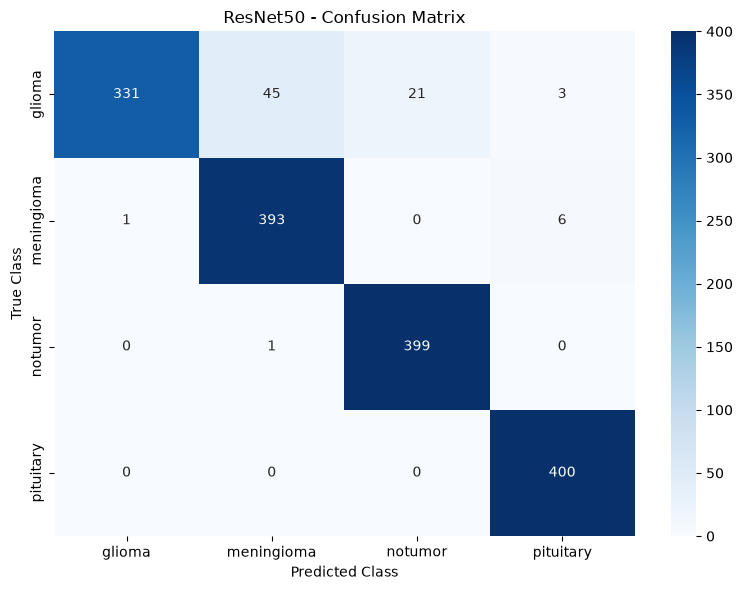

Confusion matrix saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\ResNet50_confusion_matrix.png


In [73]:
plot_confusion_matrix(
    resnet50_y_true,
    resnet50_y_pred,
    "ResNet50"
)

In [74]:
resnet50_report = generate_classification_report(
    resnet50_y_true,
    resnet50_y_pred,
    "ResNet50"
)

display(resnet50_report)


ResNet50 - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9970    0.8275    0.9044       400
  meningioma     0.8952    0.9825    0.9368       400
     notumor     0.9500    0.9975    0.9732       400
   pituitary     0.9780    1.0000    0.9889       400

    accuracy                         0.9519      1600
   macro avg     0.9550    0.9519    0.9508      1600
weighted avg     0.9550    0.9519    0.9508      1600

Classification report saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\ResNet50_classification_report.csv


,precision,recall,f1-score,support
glioma,0.996988,0.827500,0.904372,400.000000
meningioma,0.895216,0.982500,0.936830,400.000000
notumor,0.950000,0.997500,0.973171,400.000000
pituitary,0.977995,1.000000,0.988875,400.000000
accuracy,0.951875,0.951875,0.951875,0.951875
macro avg,0.955050,0.951875,0.950812,1600.000000
weighted avg,0.955050,0.951875,0.950812,1600.000000


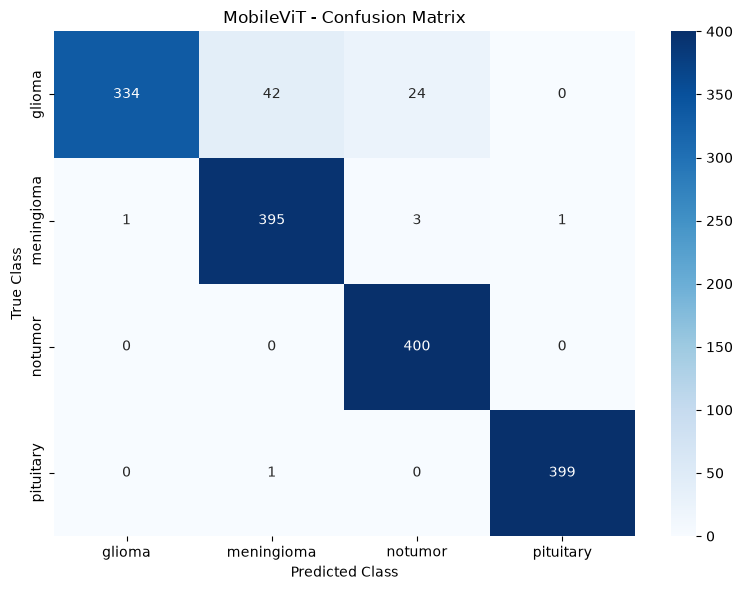

Confusion matrix saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\MobileViT_confusion_matrix.png


In [75]:
plot_confusion_matrix(
    mobilevit_y_true,
    mobilevit_y_pred,
    "MobileViT"
)

In [76]:
mobilevit_report = generate_classification_report(
    mobilevit_y_true,
    mobilevit_y_pred,
    "MobileViT"
)

display(mobilevit_report)


MobileViT - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9970    0.8350    0.9088       400
  meningioma     0.9018    0.9875    0.9427       400
     notumor     0.9368    1.0000    0.9674       400
   pituitary     0.9975    0.9975    0.9975       400

    accuracy                         0.9550      1600
   macro avg     0.9583    0.9550    0.9541      1600
weighted avg     0.9583    0.9550    0.9541      1600

Classification report saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\MobileViT_classification_report.csv


,precision,recall,f1-score,support
glioma,0.997015,0.8350,0.908844,400.000
meningioma,0.901826,0.9875,0.942721,400.000
notumor,0.936768,1.0000,0.967352,400.000
pituitary,0.997500,0.9975,0.997500,400.000
accuracy,0.955000,0.9550,0.955000,0.955
macro avg,0.958277,0.9550,0.954104,1600.000
weighted avg,0.958277,0.9550,0.954104,1600.000


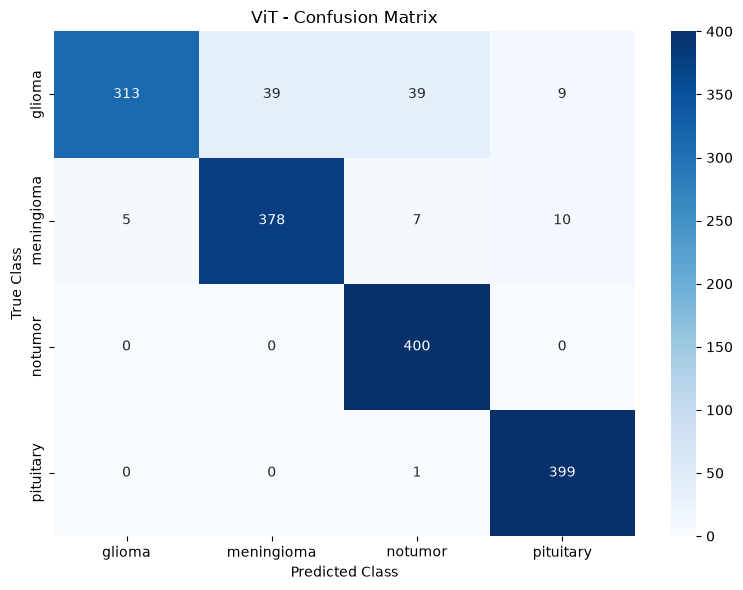

Confusion matrix saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\ViT_confusion_matrix.png


In [77]:
plot_confusion_matrix(
    vit_y_true,
    vit_y_pred,
    "ViT"
)

In [78]:
vit_report = generate_classification_report(
    vit_y_true,
    vit_y_pred,
    "ViT"
)

display(vit_report)


ViT - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9843    0.7825    0.8719       400
  meningioma     0.9065    0.9450    0.9253       400
     notumor     0.8949    1.0000    0.9445       400
   pituitary     0.9545    0.9975    0.9756       400

    accuracy                         0.9313      1600
   macro avg     0.9350    0.9313    0.9293      1600
weighted avg     0.9350    0.9313    0.9293      1600

Classification report saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\ViT_classification_report.csv


,precision,recall,f1-score,support
glioma,0.984277,0.78250,0.871866,400.00000
meningioma,0.906475,0.94500,0.925337,400.00000
notumor,0.894855,1.00000,0.944510,400.00000
pituitary,0.954545,0.99750,0.975550,400.00000
accuracy,0.931250,0.93125,0.931250,0.93125
macro avg,0.935038,0.93125,0.929316,1600.00000
weighted avg,0.935038,0.93125,0.929316,1600.00000


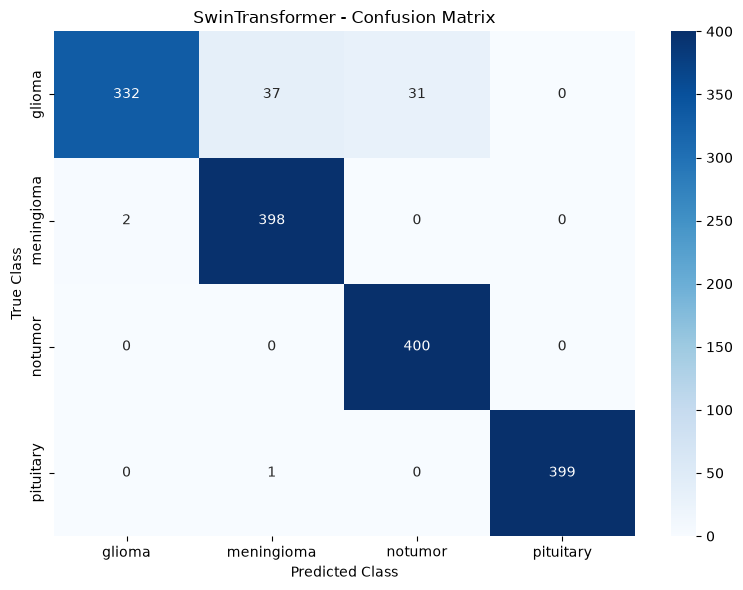

Confusion matrix saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\SwinTransformer_confusion_matrix.png


In [79]:
plot_confusion_matrix(
    swin_y_true,
    swin_y_pred,
    "SwinTransformer"
)

In [80]:
swin_report = generate_classification_report(
    swin_y_true,
    swin_y_pred,
    "SwinTransformer"
)

display(swin_report)


SwinTransformer - CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9940    0.8300    0.9046       400
  meningioma     0.9128    0.9950    0.9522       400
     notumor     0.9281    1.0000    0.9627       400
   pituitary     1.0000    0.9975    0.9987       400

    accuracy                         0.9556      1600
   macro avg     0.9587    0.9556    0.9546      1600
weighted avg     0.9587    0.9556    0.9546      1600

Classification report saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\confusion_matrices\SwinTransformer_classification_report.csv


,precision,recall,f1-score,support
glioma,0.994012,0.830000,0.904632,400.000000
meningioma,0.912844,0.995000,0.952153,400.000000
notumor,0.928074,1.000000,0.962696,400.000000
pituitary,1.000000,0.997500,0.998748,400.000000
accuracy,0.955625,0.955625,0.955625,0.955625
macro avg,0.958733,0.955625,0.954557,1600.000000
weighted avg,0.958733,0.955625,0.954557,1600.000000


In [81]:
def prepare_roc_data(
    y_true,
    y_prob
):

    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    fpr = {}
    tpr = {}
    roc_auc_values = {}

    for i, class_name in enumerate(CLASS_NAMES):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_binary[:, i],
            y_prob[:, i]
        )

        roc_auc_values[i] = auc(
            fpr[i],
            tpr[i]
        )

    return (
        y_true_binary,
        fpr,
        tpr,
        roc_auc_values
    )

print("ROC data preparation function created successfully.")

ROC data preparation function created successfully.


In [82]:
def plot_roc_curve(
    y_true,
    y_prob,
    model_name
):

    (
        y_true_binary,
        fpr,
        tpr,
        roc_auc_values
    ) = prepare_roc_data(
        y_true,
        y_prob
    )

    plt.figure(figsize=(9, 7))

    for i, class_name in enumerate(CLASS_NAMES):

        plt.plot(
            fpr[i],
            tpr[i],
            label=f"{class_name} (AUC = {roc_auc_values[i]:.4f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Random Classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        f"{model_name} - ROC Curve"
    )

    plt.legend(
        loc="lower right"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()

    save_path = (
        ROC_DIR
        / f"{model_name}_ROC.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"ROC curve saved to:\n{save_path}"
    )

    return roc_auc_values

print("ROC plotting function created successfully.")

ROC plotting function created successfully.


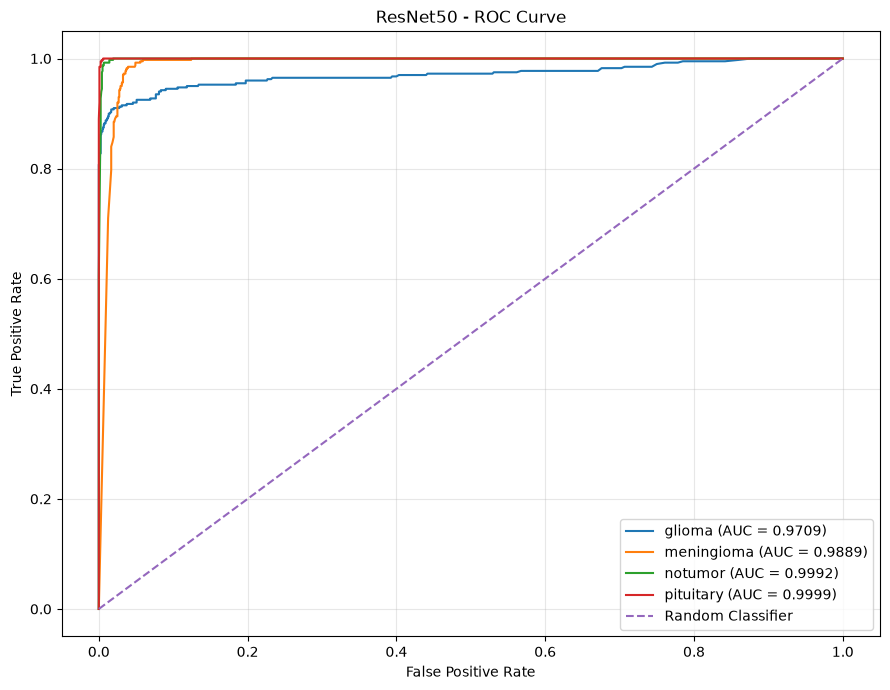

ROC curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\ResNet50_ROC.png

ResNet50 per-class ROC-AUC:
glioma      : 0.9709
meningioma  : 0.9889
notumor     : 0.9992
pituitary   : 0.9999


In [83]:
resnet50_roc_auc = plot_roc_curve(
    resnet50_y_true,
    resnet50_y_prob,
    "ResNet50"
)

print("\nResNet50 per-class ROC-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{resnet50_roc_auc[i]:.4f}"
    )

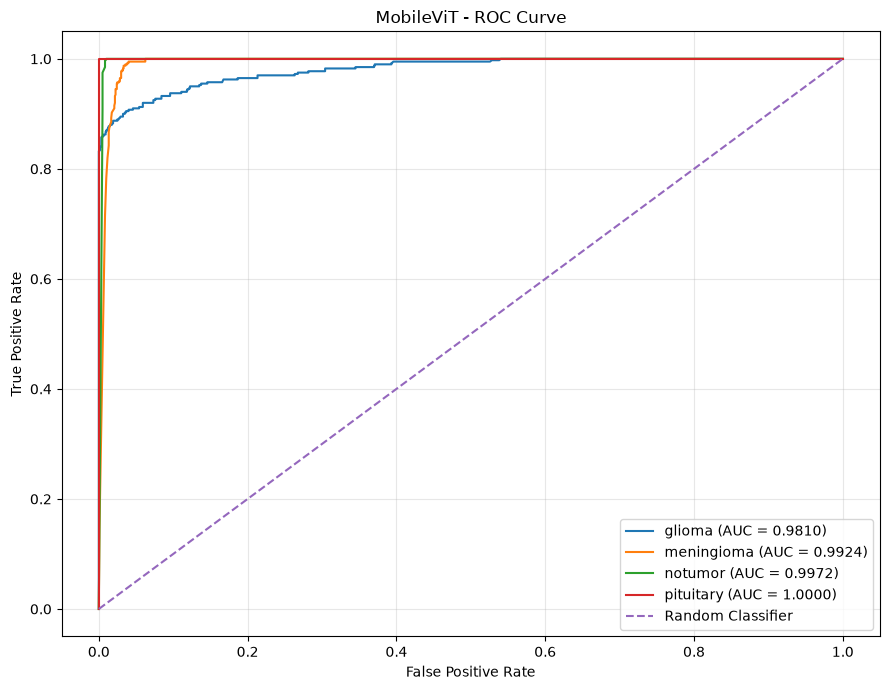

ROC curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\MobileViT_ROC.png

MobileViT per-class ROC-AUC:
glioma      : 0.9810
meningioma  : 0.9924
notumor     : 0.9972
pituitary   : 1.0000


In [84]:
mobilevit_roc_auc = plot_roc_curve(
    mobilevit_y_true,
    mobilevit_y_prob,
    "MobileViT"
)

print("\nMobileViT per-class ROC-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{mobilevit_roc_auc[i]:.4f}"
    )

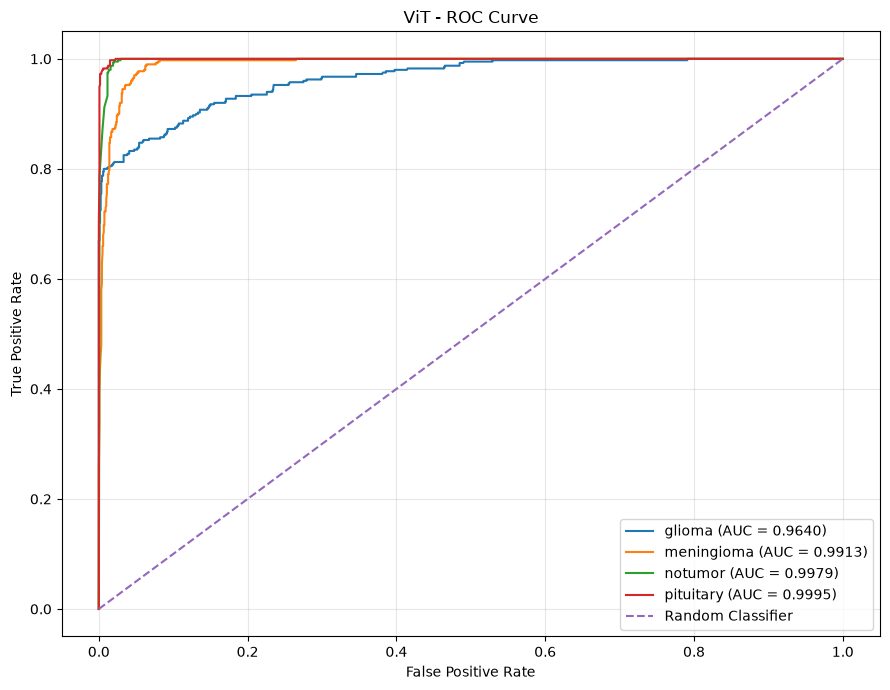

ROC curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\ViT_ROC.png

ViT per-class ROC-AUC:
glioma      : 0.9640
meningioma  : 0.9913
notumor     : 0.9979
pituitary   : 0.9995


In [85]:
vit_roc_auc = plot_roc_curve(
    vit_y_true,
    vit_y_prob,
    "ViT"
)

print("\nViT per-class ROC-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{vit_roc_auc[i]:.4f}"
    )

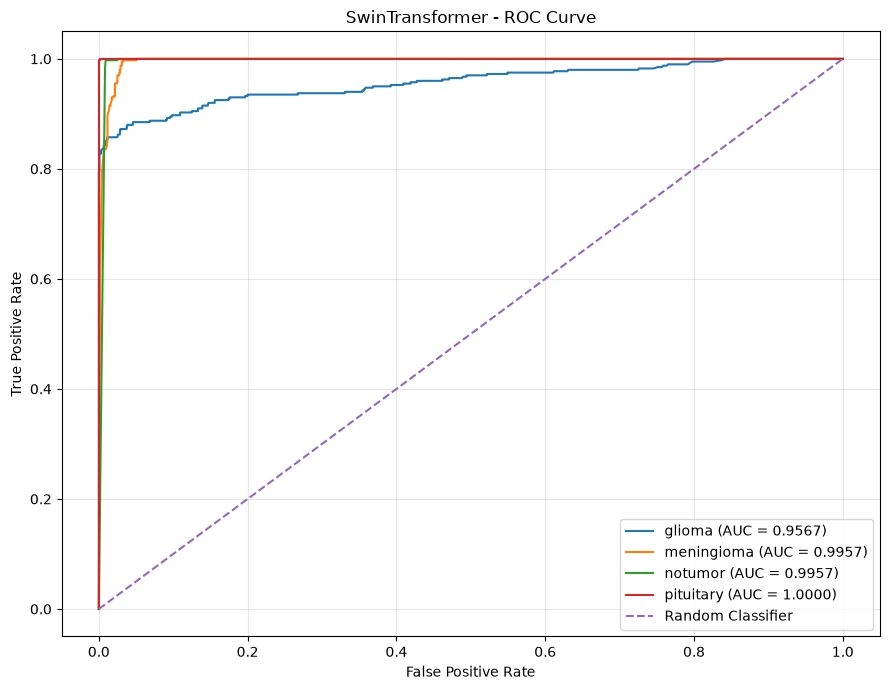

ROC curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\SwinTransformer_ROC.png

Swin Transformer per-class ROC-AUC:
glioma      : 0.9567
meningioma  : 0.9957
notumor     : 0.9957
pituitary   : 1.0000


In [86]:
swin_roc_auc = plot_roc_curve(
    swin_y_true,
    swin_y_prob,
    "SwinTransformer"
)

print("\nSwin Transformer per-class ROC-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{swin_roc_auc[i]:.4f}"
    )

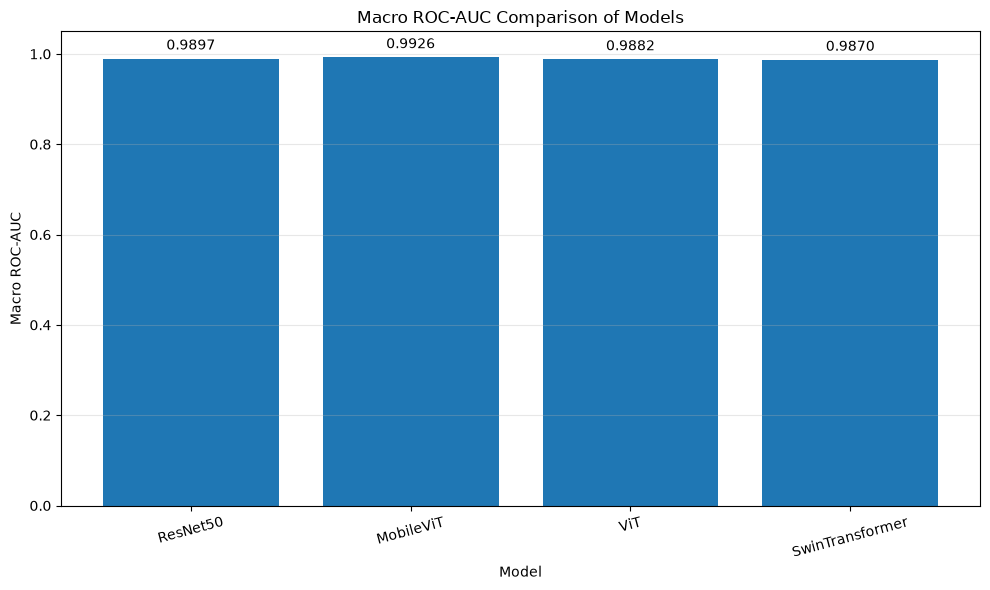

In [87]:
model_names = [
    "ResNet50",
    "MobileViT",
    "ViT",
    "SwinTransformer"
]

macro_roc_auc = [
    resnet50_metrics["ROC AUC"],
    mobilevit_metrics["ROC AUC"],
    vit_metrics["ROC AUC"],
    swin_metrics["ROC AUC"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    macro_roc_auc
)

plt.ylabel("Macro ROC-AUC")
plt.xlabel("Model")

plt.title(
    "Macro ROC-AUC Comparison of Models"
)

plt.ylim(0, 1.05)

plt.xticks(
    rotation=15
)

for bar, value in zip(
    bars,
    macro_roc_auc
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ROC_DIR / "model_roc_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
roc_auc_table = pd.DataFrame({

    "Class": CLASS_NAMES,

    "ResNet50": [
        resnet50_roc_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "MobileViT": [
        mobilevit_roc_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "ViT": [
        vit_roc_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "SwinTransformer": [
        swin_roc_auc[i]
        for i in range(NUM_CLASSES)
    ]
})

roc_auc_table = roc_auc_table.round(4)

display(roc_auc_table)

,Class,ResNet50,MobileViT,ViT,SwinTransformer
0,glioma,0.9709,0.9810,0.9640,0.9567
1,meningioma,0.9889,0.9924,0.9913,0.9957
2,notumor,0.9992,0.9972,0.9979,0.9957
3,pituitary,0.9999,1.0000,0.9995,1.0000


In [89]:
roc_auc_path = (
    ROC_DIR / "roc_auc_comparison.csv"
)

roc_auc_table.to_csv(
    roc_auc_path,
    index=False
)

print(
    "ROC-AUC comparison saved to:"
)

print(roc_auc_path)

ROC-AUC comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\roc_auc_comparison.csv


In [90]:
del resnet50_roc_auc
del mobilevit_roc_auc
del vit_roc_auc
del swin_roc_auc

gc.collect()

print("ROC analysis completed successfully.")

ROC analysis completed successfully.


In [91]:
def prepare_pr_data(
    y_true,
    y_prob
):

    y_true_binary = label_binarize(
        y_true,
        classes=np.arange(NUM_CLASSES)
    )

    precision = {}
    recall = {}
    pr_auc_values = {}

    for i, class_name in enumerate(CLASS_NAMES):

        precision[i], recall[i], _ = precision_recall_curve(
            y_true_binary[:, i],
            y_prob[:, i]
        )

        pr_auc_values[i] = auc(
            recall[i],
            precision[i]
        )

    return (
        y_true_binary,
        precision,
        recall,
        pr_auc_values
    )

print("Precision-Recall data preparation function created successfully.")

Precision-Recall data preparation function created successfully.


In [92]:
def plot_pr_curve(
    y_true,
    y_prob,
    model_name
):

    (
        y_true_binary,
        precision,
        recall,
        pr_auc_values
    ) = prepare_pr_data(
        y_true,
        y_prob
    )

    plt.figure(figsize=(9, 7))

    for i, class_name in enumerate(CLASS_NAMES):

        plt.plot(
            recall[i],
            precision[i],
            label=f"{class_name} (AUC = {pr_auc_values[i]:.4f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.title(
        f"{model_name} - Precision-Recall Curve"
    )

    plt.legend(
        loc="lower left"
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()

    save_path = (
        PR_DIR
        / f"{model_name}_PR.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Precision-Recall curve saved to:\n{save_path}"
    )

    return pr_auc_values

print("Precision-Recall plotting function created successfully.")

Precision-Recall plotting function created successfully.


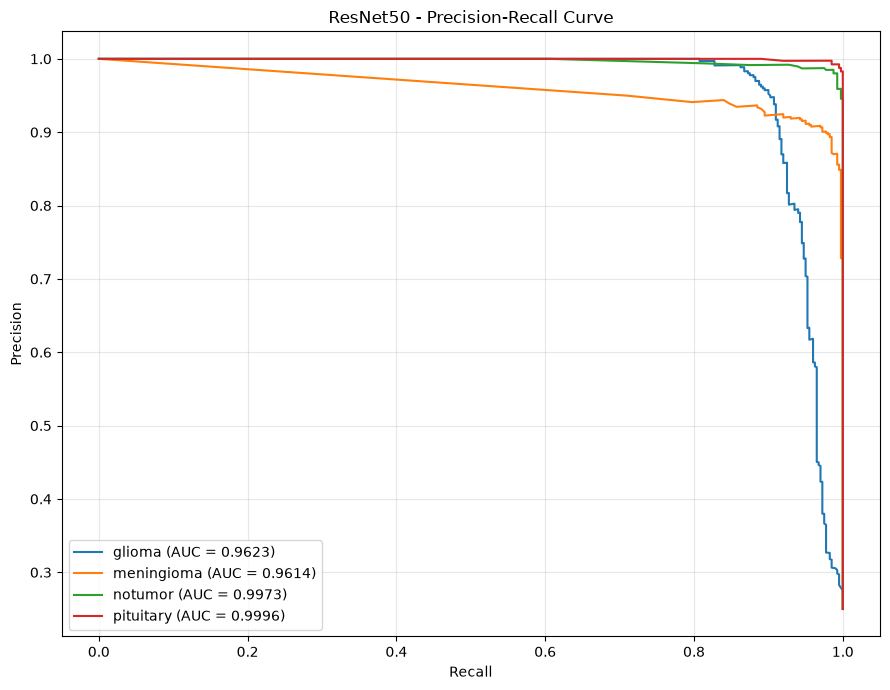

Precision-Recall curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\ResNet50_PR.png

ResNet50 per-class PR-AUC:
glioma      : 0.9623
meningioma  : 0.9614
notumor     : 0.9973
pituitary   : 0.9996


In [93]:
resnet50_pr_auc = plot_pr_curve(
    resnet50_y_true,
    resnet50_y_prob,
    "ResNet50"
)

print("\nResNet50 per-class PR-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{resnet50_pr_auc[i]:.4f}"
    )

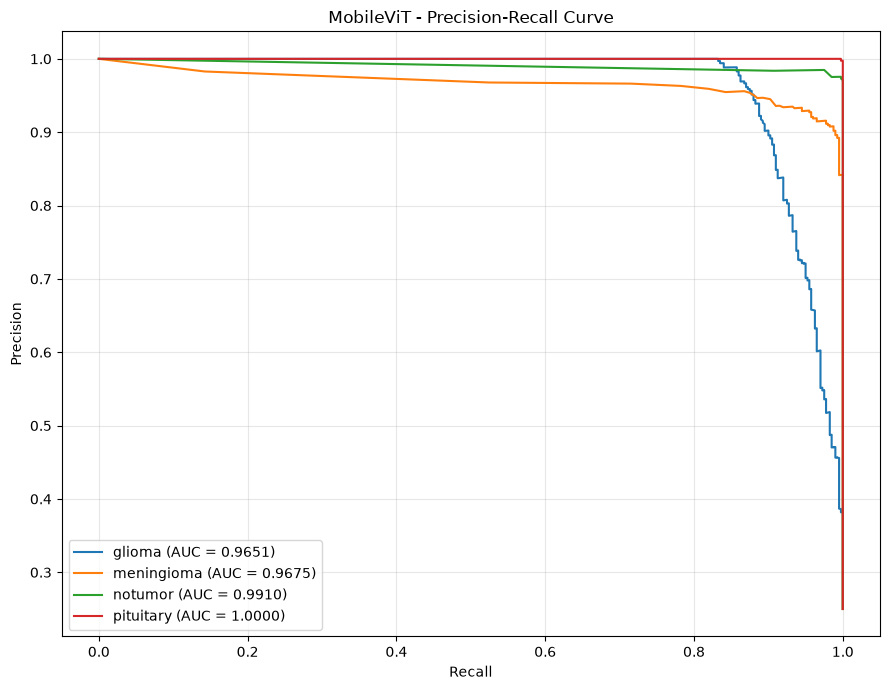

Precision-Recall curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\MobileViT_PR.png

MobileViT per-class PR-AUC:
glioma      : 0.9651
meningioma  : 0.9675
notumor     : 0.9910
pituitary   : 1.0000


In [94]:
mobilevit_pr_auc = plot_pr_curve(
    mobilevit_y_true,
    mobilevit_y_prob,
    "MobileViT"
)

print("\nMobileViT per-class PR-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{mobilevit_pr_auc[i]:.4f}"
    )

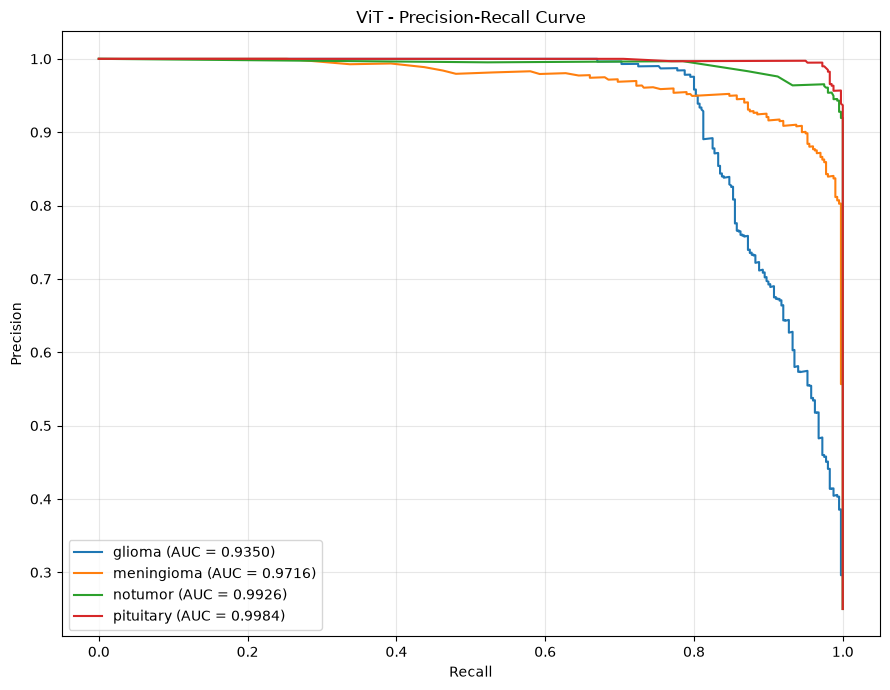

Precision-Recall curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\ViT_PR.png

ViT per-class PR-AUC:
glioma      : 0.9350
meningioma  : 0.9716
notumor     : 0.9926
pituitary   : 0.9984


In [95]:
vit_pr_auc = plot_pr_curve(
    vit_y_true,
    vit_y_prob,
    "ViT"
)

print("\nViT per-class PR-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{vit_pr_auc[i]:.4f}"
    )

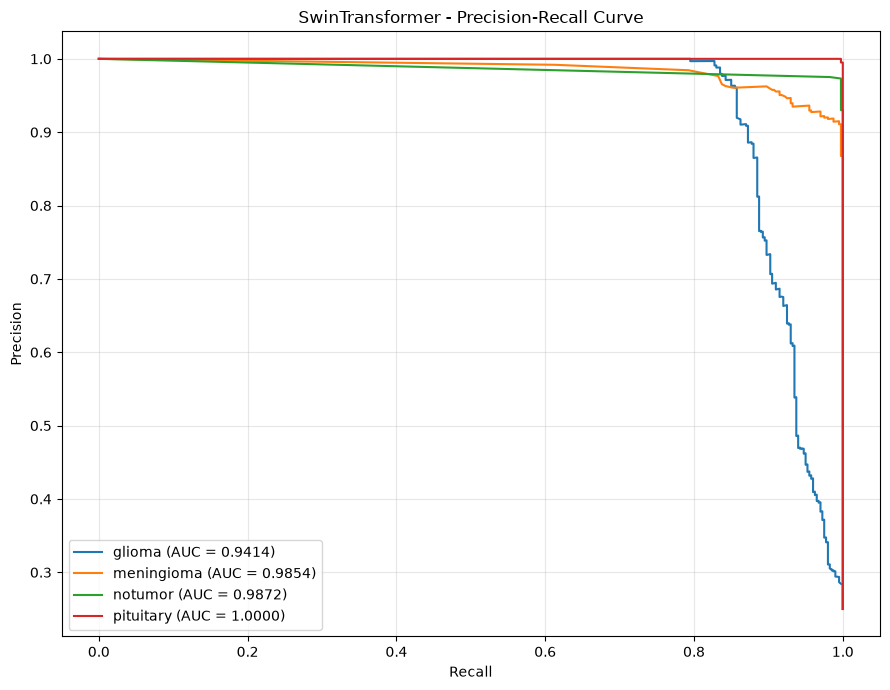

Precision-Recall curve saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\SwinTransformer_PR.png

Swin Transformer per-class PR-AUC:
glioma      : 0.9414
meningioma  : 0.9854
notumor     : 0.9872
pituitary   : 1.0000


In [96]:
swin_pr_auc = plot_pr_curve(
    swin_y_true,
    swin_y_prob,
    "SwinTransformer"
)

print("\nSwin Transformer per-class PR-AUC:")

for i, class_name in enumerate(CLASS_NAMES):

    print(
        f"{class_name:12s}: "
        f"{swin_pr_auc[i]:.4f}"
    )

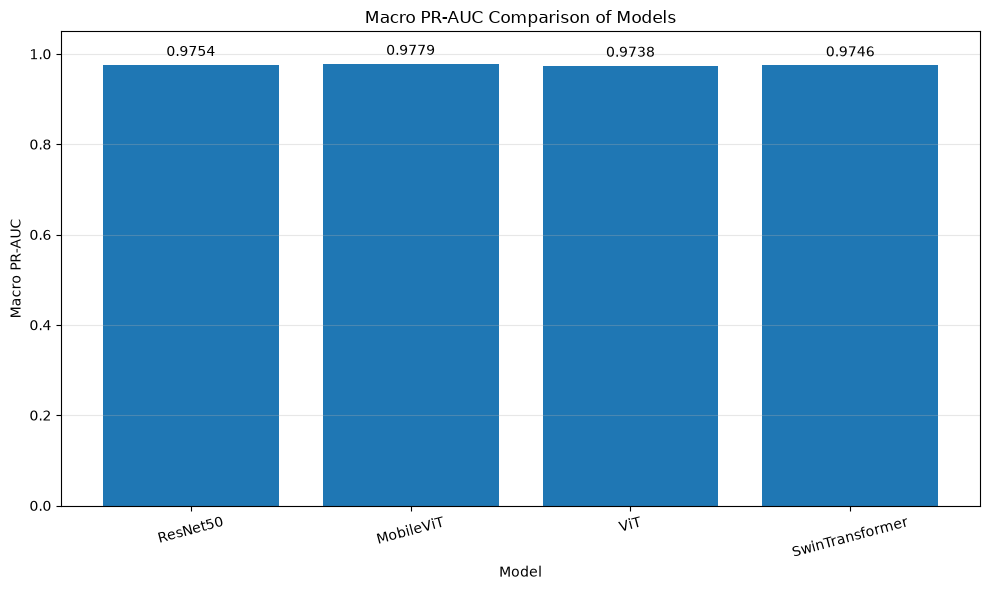

In [97]:
model_names = [
    "ResNet50",
    "MobileViT",
    "ViT",
    "SwinTransformer"
]

macro_pr_auc = [
    resnet50_metrics["PR AUC"],
    mobilevit_metrics["PR AUC"],
    vit_metrics["PR AUC"],
    swin_metrics["PR AUC"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    model_names,
    macro_pr_auc
)

plt.ylabel("Macro PR-AUC")
plt.xlabel("Model")

plt.title(
    "Macro PR-AUC Comparison of Models"
)

plt.ylim(0, 1.05)

plt.xticks(
    rotation=15
)

for bar, value in zip(
    bars,
    macro_pr_auc
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.4f}",
        ha="center"
    )

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    PR_DIR / "model_pr_auc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [98]:
pr_auc_table = pd.DataFrame({

    "Class": CLASS_NAMES,

    "ResNet50": [
        resnet50_pr_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "MobileViT": [
        mobilevit_pr_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "ViT": [
        vit_pr_auc[i]
        for i in range(NUM_CLASSES)
    ],

    "SwinTransformer": [
        swin_pr_auc[i]
        for i in range(NUM_CLASSES)
    ]
})

pr_auc_table = pr_auc_table.round(4)

display(pr_auc_table)

,Class,ResNet50,MobileViT,ViT,SwinTransformer
0,glioma,0.9623,0.9651,0.9350,0.9414
1,meningioma,0.9614,0.9675,0.9716,0.9854
2,notumor,0.9973,0.9910,0.9926,0.9872
3,pituitary,0.9996,1.0000,0.9984,1.0000


In [99]:
pr_auc_path = (
    PR_DIR / "pr_auc_comparison.csv"
)

pr_auc_table.to_csv(
    pr_auc_path,
    index=False
)

print(
    "PR-AUC comparison saved to:"
)

print(pr_auc_path)

PR-AUC comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\pr_auc_comparison.csv


Image path: c:\Users\Apurv\Desktop\Dataset_29\Testing\glioma\Te-gl_1.jpg
True class: glioma
Input shape: torch.Size([1, 3, 224, 224])


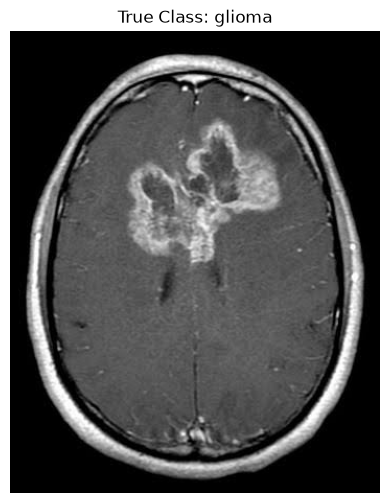

In [100]:
# Select one test image
sample_index = 0

image_path, true_label = test_dataset.samples[sample_index]

original_image = Image.open(
    image_path
).convert("RGB")

input_tensor = test_transform(
    original_image
).unsqueeze(0).to(DEVICE)

print("Image path:", image_path)
print("True class:", CLASS_NAMES[true_label])
print("Input shape:", input_tensor.shape)

plt.figure(figsize=(6, 6))

plt.imshow(original_image)

plt.title(
    f"True Class: {CLASS_NAMES[true_label]}"
)

plt.axis("off")
plt.show()

In [101]:
def get_gradcam_target_layer(
    model,
    model_name
):

    if model_name == "ResNet50":

        target_layer = model.layer4[-1]

    elif model_name == "MobileViT":

        target_layer = model.stages[-1]

    elif model_name == "ViT":

        target_layer = model.blocks[-1].norm1

    elif model_name == "SwinTransformer":

        target_layer = (
            model.layers[-1]
            .blocks[-1]
            .norm1
        )

    else:

        raise ValueError(
            f"Unsupported model: {model_name}"
        )

    return target_layer


print("Grad-CAM target layer selector created.")

Grad-CAM target layer selector created.


In [102]:
def reshape_gradcam_activation(
    activation
):

    # CNN-style feature map:
    # [B, C, H, W]
    if activation.ndim == 4:

        # Check whether format is B,H,W,C
        if (
            activation.shape[1]
            < activation.shape[2]
            and activation.shape[1]
            < activation.shape[3]
        ):

            activation = activation.permute(
                0, 3, 1, 2
            )

        return activation

    # Transformer-style representation:
    # [B, N, C]
    elif activation.ndim == 3:

        batch_size, num_tokens, channels = (
            activation.shape
        )

        # Remove CLS token if present
        grid_tokens = num_tokens - 1

        grid_size = int(
            math.sqrt(grid_tokens)
        )

        if grid_size * grid_size == grid_tokens:

            activation = activation[:, 1:, :]

        else:

            grid_size = int(
                math.sqrt(num_tokens)
            )

            if grid_size * grid_size != num_tokens:

                raise ValueError(
                    f"Cannot reshape activation "
                    f"with shape {activation.shape}"
                )

        activation = activation.reshape(
            batch_size,
            grid_size,
            grid_size,
            channels
        )

        activation = activation.permute(
            0, 3, 1, 2
        )

        return activation

    else:

        raise ValueError(
            f"Unsupported activation shape: "
            f"{activation.shape}"
        )


print("Activation reshape function created.")

Activation reshape function created.


In [103]:
class GradCAM:

    def __init__(
        self,
        model,
        target_layer
    ):

        self.model = model
        self.target_layer = target_layer

        self.activation = None
        self.gradient = None

        self.forward_handle = (
            target_layer.register_forward_hook(
                self.save_activation
            )
        )

        self.backward_handle = (
            target_layer.register_full_backward_hook(
                self.save_gradient
            )
        )

    def save_activation(
        self,
        module,
        input,
        output
    ):

        self.activation = output

    def save_gradient(
        self,
        module,
        grad_input,
        grad_output
    ):

        self.gradient = grad_output[0]

    def generate(
        self,
        input_tensor,
        target_class
    ):

        self.model.eval()

        self.model.zero_grad(
            set_to_none=True
        )

        output = self.model(
            input_tensor
        )

        target_score = output[
            0,
            target_class
        ]

        target_score.backward()

        activation = self.activation
        gradient = self.gradient

        activation = reshape_gradcam_activation(
            activation
        )

        gradient = reshape_gradcam_activation(
            gradient
        )

        # Global average pooling of gradients
        weights = gradient.mean(
            dim=(2, 3),
            keepdim=True
        )

        cam = (
            weights * activation
        ).sum(
            dim=1,
            keepdim=True
        )

        cam = torch.relu(cam)

        cam = torch.nn.functional.interpolate(
            cam,
            size=(
                IMAGE_SIZE,
                IMAGE_SIZE
            ),
            mode="bilinear",
            align_corners=False
        )

        cam = cam.squeeze()

        cam = cam.detach().cpu().numpy()

        # Normalize between 0 and 1
        cam = (
            cam - cam.min()
        ) / (
            cam.max()
            - cam.min()
            + 1e-8
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=1
        ).item()

        confidence = probabilities[
            0,
            predicted_class
        ].item()

        return (
            cam,
            predicted_class,
            confidence
        )

    def remove_hooks(self):

        self.forward_handle.remove()
        self.backward_handle.remove()


print("Grad-CAM implementation created successfully.")

Grad-CAM implementation created successfully.


In [104]:
def visualize_gradcam(
    original_image,
    cam,
    true_class,
    predicted_class,
    confidence,
    model_name
):

    image = np.array(
        original_image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )
    ) / 255.0

    plt.figure(figsize=(15, 5))

    # Original image
    plt.subplot(1, 3, 1)

    plt.imshow(image)

    plt.title(
        f"Original\n"
        f"True: {CLASS_NAMES[true_class]}"
    )

    plt.axis("off")

    # Grad-CAM heatmap
    plt.subplot(1, 3, 2)

    plt.imshow(
        cam,
        cmap="jet"
    )

    plt.title(
        "Grad-CAM Heatmap"
    )

    plt.axis("off")

    # Overlay
    plt.subplot(1, 3, 3)

    plt.imshow(image)

    plt.imshow(
        cam,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"{model_name}\n"
        f"Predicted: {CLASS_NAMES[predicted_class]}\n"
        f"Confidence: {confidence:.2%}"
    )

    plt.axis("off")

    plt.tight_layout()

    save_path = (
        GRADCAM_DIR
        / f"{model_name}_gradcam.png"
    )

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(
        f"Grad-CAM saved to:\n{save_path}"
    )

In [105]:
resnet50_model = create_resnet50(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "ResNet50.pth",
    map_location=DEVICE
)

resnet50_model.load_state_dict(
    checkpoint["model_state_dict"]
)

resnet50_model = resnet50_model.to(
    DEVICE
)

resnet50_model.eval()

resnet50_target_layer = (
    get_gradcam_target_layer(
        resnet50_model,
        "ResNet50"
    )
)

print(
    "ResNet50 Grad-CAM target layer:"
)

print(
    resnet50_target_layer
)

ResNet50 Grad-CAM target layer:
Bottleneck(
  (conv1): Conv2d(2048, 512, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)
  (bn3): BatchNorm2d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
)


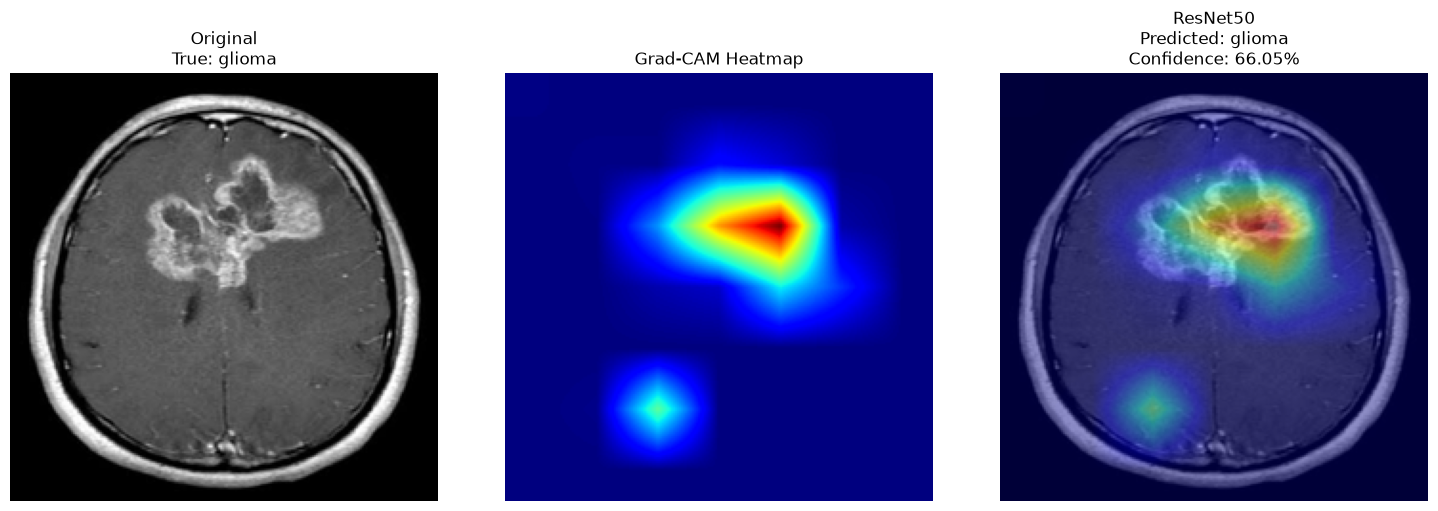

Grad-CAM saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\ResNet50_gradcam.png


In [106]:
resnet50_gradcam = GradCAM(
    resnet50_model,
    resnet50_target_layer
)

(
    resnet50_cam,
    resnet50_predicted_class,
    resnet50_confidence
) = resnet50_gradcam.generate(
    input_tensor,
    true_label
)

visualize_gradcam(
    original_image,
    resnet50_cam,
    true_label,
    resnet50_predicted_class,
    resnet50_confidence,
    "ResNet50"
)

resnet50_gradcam.remove_hooks()

In [107]:
del resnet50_gradcam
del resnet50_model
del resnet50_target_layer
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print(
    "ResNet50 Grad-CAM resources cleared."
)

ResNet50 Grad-CAM resources cleared.


In [108]:
mobilevit_model = create_mobilevit(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "MobileViT.pth",
    map_location=DEVICE
)

mobilevit_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mobilevit_model = mobilevit_model.to(
    DEVICE
)

mobilevit_model.eval()

mobilevit_target_layer = (
    get_gradcam_target_layer(
        mobilevit_model,
        "MobileViT"
    )
)

print(
    "MobileViT Grad-CAM target layer:"
)

print(
    mobilevit_target_layer
)

MobileViT Grad-CAM target layer:
Sequential(
  (0): BottleneckBlock(
    (conv1_1x1): ConvNormAct(
      (conv): Conv2d(80, 320, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        320, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        (act): SiLU(inplace=True)
      )
    )
    (conv2_kxk): ConvNormAct(
      (conv): Conv2d(320, 320, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=320, bias=False)
      (bn): BatchNormAct2d(
        320, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        (act): SiLU(inplace=True)
      )
    )
    (conv2b_kxk): Identity()
    (attn): Identity()
    (conv3_1x1): ConvNormAct(
      (conv): Conv2d(320, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn): BatchNormAct2d(
        96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True
        (drop): Identity()
        

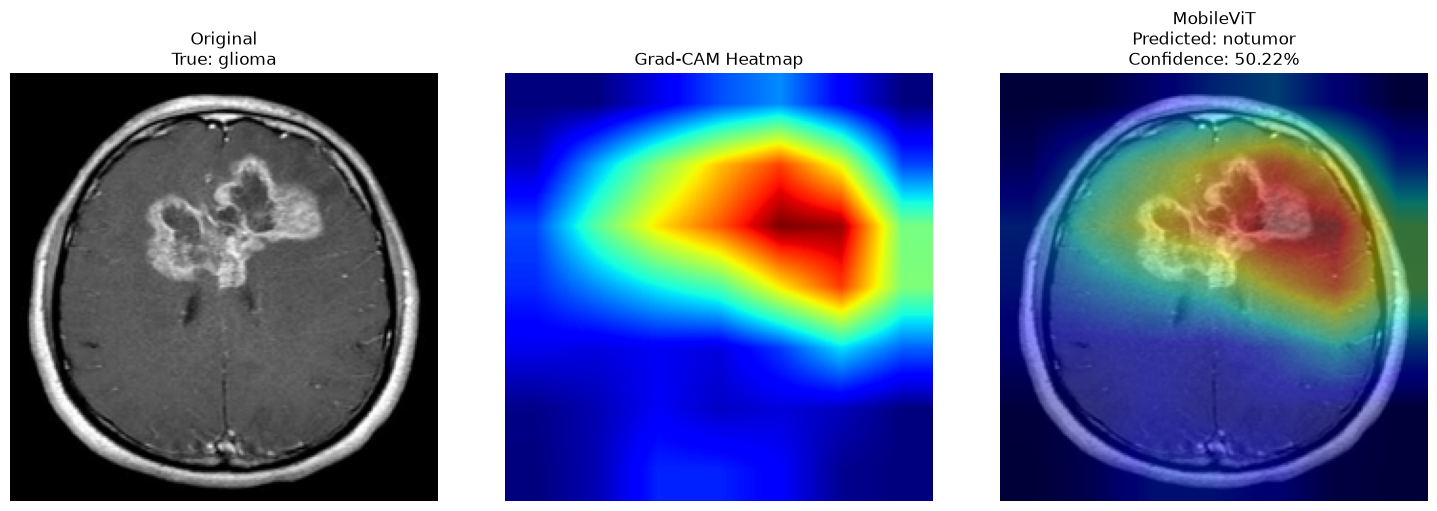

Grad-CAM saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\MobileViT_gradcam.png


In [109]:
mobilevit_gradcam = GradCAM(
    mobilevit_model,
    mobilevit_target_layer
)

(
    mobilevit_cam,
    mobilevit_predicted_class,
    mobilevit_confidence
) = mobilevit_gradcam.generate(
    input_tensor,
    true_label
)

visualize_gradcam(
    original_image,
    mobilevit_cam,
    true_label,
    mobilevit_predicted_class,
    mobilevit_confidence,
    "MobileViT"
)

mobilevit_gradcam.remove_hooks()

In [110]:
vit_model = create_vit(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "ViT.pth",
    map_location=DEVICE
)

vit_model.load_state_dict(
    checkpoint["model_state_dict"]
)

vit_model = vit_model.to(DEVICE)

vit_model.eval()

vit_target_layer = (
    get_gradcam_target_layer(
        vit_model,
        "ViT"
    )
)

print("ViT Grad-CAM target layer:")
print(vit_target_layer)

ViT Grad-CAM target layer:
LayerNorm((768,), eps=1e-06, elementwise_affine=True, bias=True)


In [111]:
vit_gradcam = GradCAM(
    vit_model,
    vit_target_layer
)

print("ViT Grad-CAM object created successfully.")

ViT Grad-CAM object created successfully.


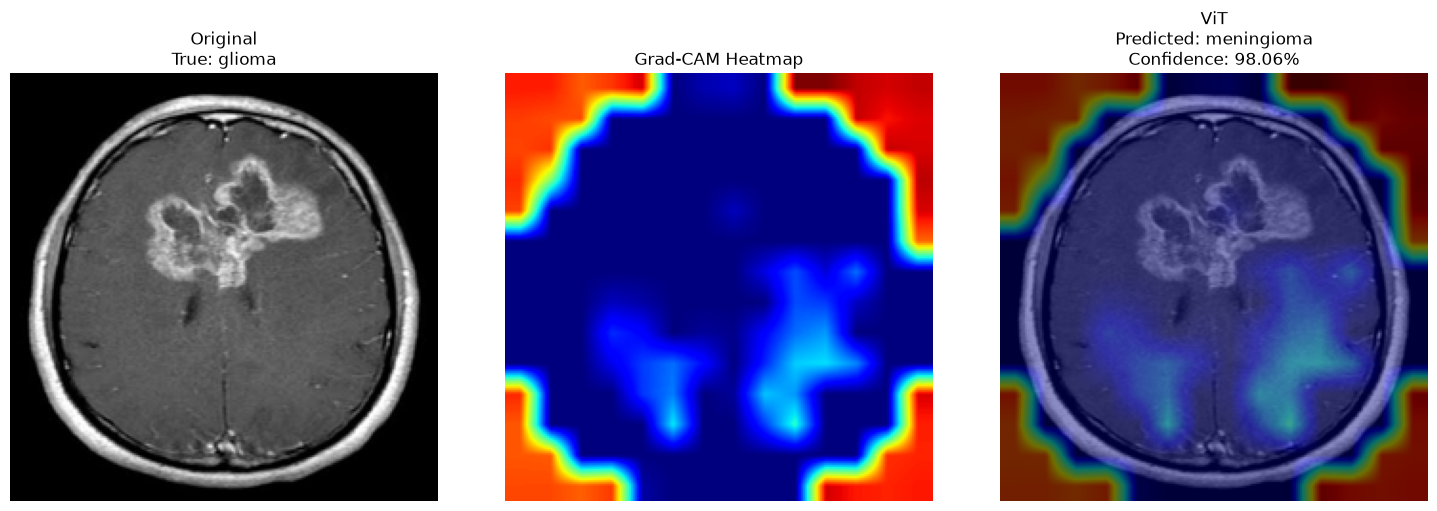

Grad-CAM saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\ViT_gradcam.png


In [112]:
(
    vit_cam,
    vit_predicted_class,
    vit_confidence
) = vit_gradcam.generate(
    input_tensor,
    true_label
)

visualize_gradcam(
    original_image,
    vit_cam,
    true_label,
    vit_predicted_class,
    vit_confidence,
    "ViT"
)

vit_gradcam.remove_hooks()

In [113]:
del vit_gradcam
del vit_model
del vit_target_layer
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print("ViT Grad-CAM resources cleared.")

ViT Grad-CAM resources cleared.


In [114]:
swin_model = create_swin(
    NUM_CLASSES
)

checkpoint = torch.load(
    MODEL_DIR / "SwinTransformer.pth",
    map_location=DEVICE
)

swin_model.load_state_dict(
    checkpoint["model_state_dict"]
)

swin_model = swin_model.to(DEVICE)

swin_model.eval()

swin_target_layer = (
    get_gradcam_target_layer(
        swin_model,
        "SwinTransformer"
    )
)

print("Swin Transformer Grad-CAM target layer:")
print(swin_target_layer)

Swin Transformer Grad-CAM target layer:
LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)


In [115]:
swin_gradcam = GradCAM(
    swin_model,
    swin_target_layer
)

print(
    "Swin Transformer Grad-CAM object "
    "created successfully."
)

Swin Transformer Grad-CAM object created successfully.


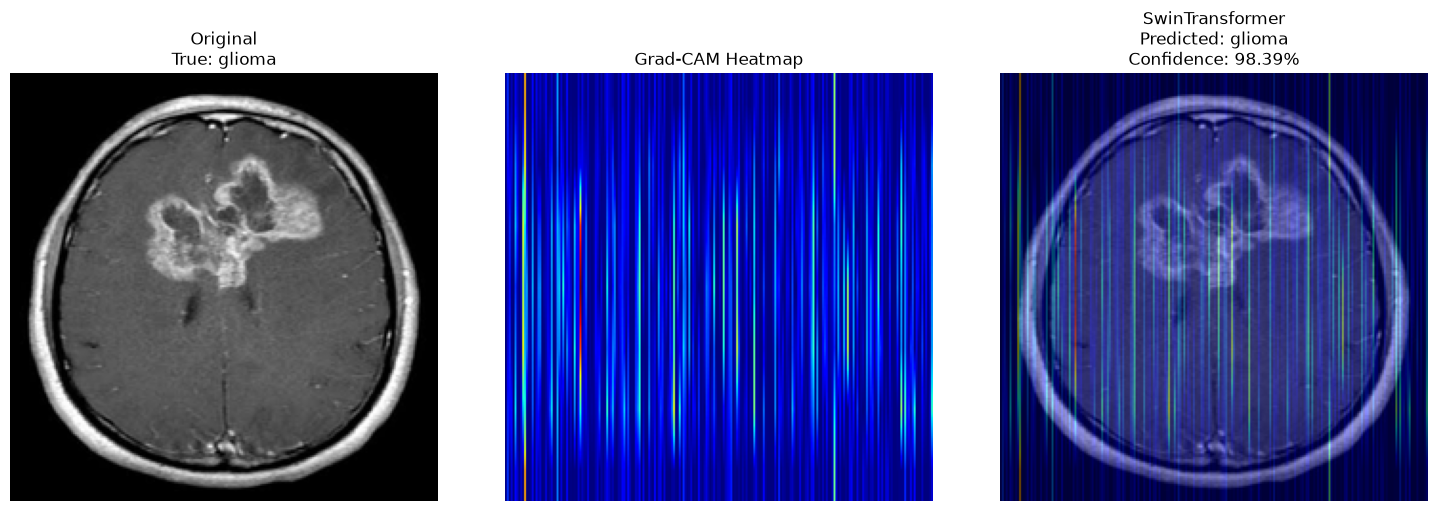

Grad-CAM saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\SwinTransformer_gradcam.png


In [116]:
(
    swin_cam,
    swin_predicted_class,
    swin_confidence
) = swin_gradcam.generate(
    input_tensor,
    true_label
)

visualize_gradcam(
    original_image,
    swin_cam,
    true_label,
    swin_predicted_class,
    swin_confidence,
    "SwinTransformer"
)

swin_gradcam.remove_hooks()

In [117]:
del swin_gradcam
del swin_model
del swin_target_layer
del checkpoint

torch.cuda.empty_cache()
gc.collect()

print(
    "Swin Transformer Grad-CAM resources cleared."
)

Swin Transformer Grad-CAM resources cleared.


In [118]:
gradcam_summary = pd.DataFrame({

    "Model": [
        "ResNet50",
        "MobileViT",
        "ViT",
        "SwinTransformer"
    ],

    "True Class": [
        CLASS_NAMES[true_label],
        CLASS_NAMES[true_label],
        CLASS_NAMES[true_label],
        CLASS_NAMES[true_label]
    ],

    "Predicted Class": [
        CLASS_NAMES[resnet50_predicted_class],
        CLASS_NAMES[mobilevit_predicted_class],
        CLASS_NAMES[vit_predicted_class],
        CLASS_NAMES[swin_predicted_class]
    ],

    "Confidence": [
        resnet50_confidence,
        mobilevit_confidence,
        vit_confidence,
        swin_confidence
    ]
})

gradcam_summary["Confidence"] = (
    gradcam_summary["Confidence"].round(4)
)

display(gradcam_summary)

,Model,True Class,Predicted Class,Confidence
0,ResNet50,glioma,glioma,0.6605
1,MobileViT,glioma,notumor,0.5022
2,ViT,glioma,meningioma,0.9806
3,SwinTransformer,glioma,glioma,0.9839


In [119]:
gradcam_summary_path = (
    GRADCAM_DIR
    / "gradcam_prediction_summary.csv"
)

gradcam_summary.to_csv(
    gradcam_summary_path,
    index=False
)

print(
    "Grad-CAM prediction summary saved to:"
)

print(gradcam_summary_path)

Grad-CAM prediction summary saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\gradcam_prediction_summary.csv


In [120]:
# Block 117 - Load Saved Model

def load_trained_model(model_name):
    if model_name not in MODEL_CREATORS:
        raise ValueError(f"Unknown model: {model_name}")

    model = MODEL_CREATORS[model_name](NUM_CLASSES)

    model_path = MODEL_DIR / f"{model_name}.pth"

    checkpoint = torch.load(
        model_path,
        map_location=DEVICE
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    print(f"{model_name} loaded successfully.")
    print(f"Model path: {model_path}")

    return model

In [121]:
# Block 118 - Single Image Prediction

def predict_single_image(model, image_path):
    image = Image.open(image_path).convert("RGB")

    input_tensor = test_transform(image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            output = model(input_tensor)

        probabilities = torch.softmax(output, dim=1)
        predicted_class = torch.argmax(probabilities, dim=1).item()

    confidence = probabilities[0, predicted_class].item()

    return (
        CLASS_NAMES[predicted_class],
        confidence,
        probabilities[0].cpu().numpy()
    )

In [122]:
# Block 119 - Select Test MRI

sample_index = 0

sample_path = test_dataset.samples[sample_index][0]
true_class_index = test_dataset.samples[sample_index][1]
true_class = CLASS_NAMES[true_class_index]

print("Sample MRI:")
print(sample_path)
print()
print("True Class:", true_class)

Sample MRI:
c:\Users\Apurv\Desktop\Dataset_29\Testing\glioma\Te-gl_1.jpg

True Class: glioma


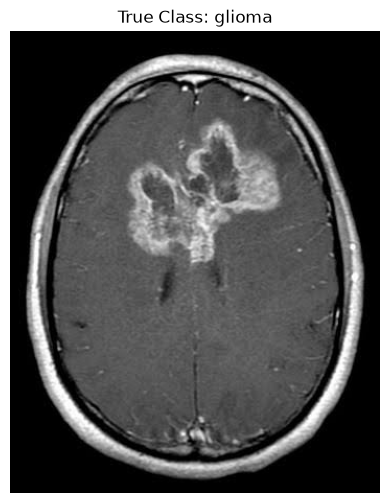

In [123]:
# Block 120 - Display Selected MRI

sample_image = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(sample_image, cmap="gray")
plt.title(f"True Class: {true_class}")
plt.axis("off")
plt.show()

In [124]:
# Block 121 - Four Model Prediction

model_predictions = []

for model_name in MODEL_CREATORS.keys():

    model = load_trained_model(model_name)

    predicted_class, confidence, probabilities = predict_single_image(
        model,
        sample_path
    )

    model_predictions.append({
        "Model": model_name,
        "True Class": true_class,
        "Predicted Class": predicted_class,
        "Confidence": confidence
    })

    del model
    torch.cuda.empty_cache()

prediction_df = pd.DataFrame(model_predictions)

prediction_df

ResNet50 loaded successfully.
Model path: c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ResNet50.pth
MobileViT loaded successfully.
Model path: c:\Users\Apurv\Desktop\Dataset_29\outputs\models\MobileViT.pth
ViT loaded successfully.
Model path: c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ViT.pth
SwinTransformer loaded successfully.
Model path: c:\Users\Apurv\Desktop\Dataset_29\outputs\models\SwinTransformer.pth


,Model,True Class,Predicted Class,Confidence
0,ResNet50,glioma,glioma,0.667480
1,MobileViT,glioma,glioma,0.493408
2,ViT,glioma,meningioma,0.980469
3,SwinTransformer,glioma,glioma,0.983887


In [125]:
# Block 122 - Save Prediction Comparison

prediction_path = OUTPUT_DIR / "single_image_prediction_comparison.csv"

prediction_df.to_csv(
    prediction_path,
    index=False
)

print("Prediction comparison saved to:")
print(prediction_path)

Prediction comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\single_image_prediction_comparison.csv


In [126]:
#  Model Comparison

comparison_df = pd.DataFrame({
    "Model": [
        "ResNet50",
        "MobileViT",
        "ViT",
        "SwinTransformer"
    ],
    "Accuracy": [
        resnet50_metrics["Accuracy"],
        mobilevit_metrics["Accuracy"],
        vit_metrics["Accuracy"],
        swin_metrics["Accuracy"]
    ],
    "Precision": [
        resnet50_metrics["Precision"],
        mobilevit_metrics["Precision"],
        vit_metrics["Precision"],
        swin_metrics["Precision"]
    ],
    "Recall": [
        resnet50_metrics["Recall"],
        mobilevit_metrics["Recall"],
        vit_metrics["Recall"],
        swin_metrics["Recall"]
    ],
    "F1 Score": [
        resnet50_metrics["F1 Score"],
        mobilevit_metrics["F1 Score"],
        vit_metrics["F1 Score"],
        swin_metrics["F1 Score"]
    ],
    "ROC AUC": [
        resnet50_metrics["ROC AUC"],
        mobilevit_metrics["ROC AUC"],
        vit_metrics["ROC AUC"],
        swin_metrics["ROC AUC"]
    ],
    "PR AUC": [
        resnet50_metrics["PR AUC"],
        mobilevit_metrics["PR AUC"],
        vit_metrics["PR AUC"],
        swin_metrics["PR AUC"]
    ]
})

display(comparison_df)

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,ResNet50,0.951875,0.955050,0.951875,0.950812,0.989711,0.975425
1,MobileViT,0.955000,0.958277,0.955000,0.954104,0.992644,0.977940
2,ViT,0.931250,0.935038,0.931250,0.929316,0.988156,0.973761
3,SwinTransformer,0.955625,0.958733,0.955625,0.954557,0.987023,0.974615


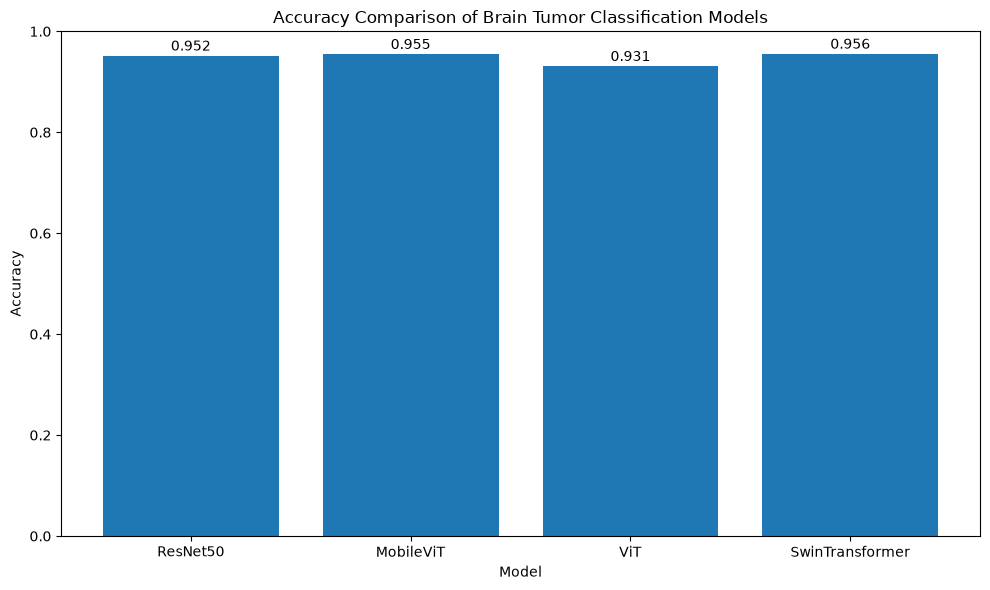

Accuracy comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\model_accuracy_comparison.png


In [127]:
# Block 123 - Model Accuracy Comparison

comparison_plot = comparison_df.copy()

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_plot["Model"],
    comparison_plot["Accuracy"]
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison of Brain Tumor Classification Models")
plt.ylim(0, 1)

for i, value in enumerate(comparison_plot["Accuracy"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

accuracy_plot_path = OUTPUT_DIR / "model_accuracy_comparison.png"

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Accuracy comparison saved to:")
print(accuracy_plot_path)

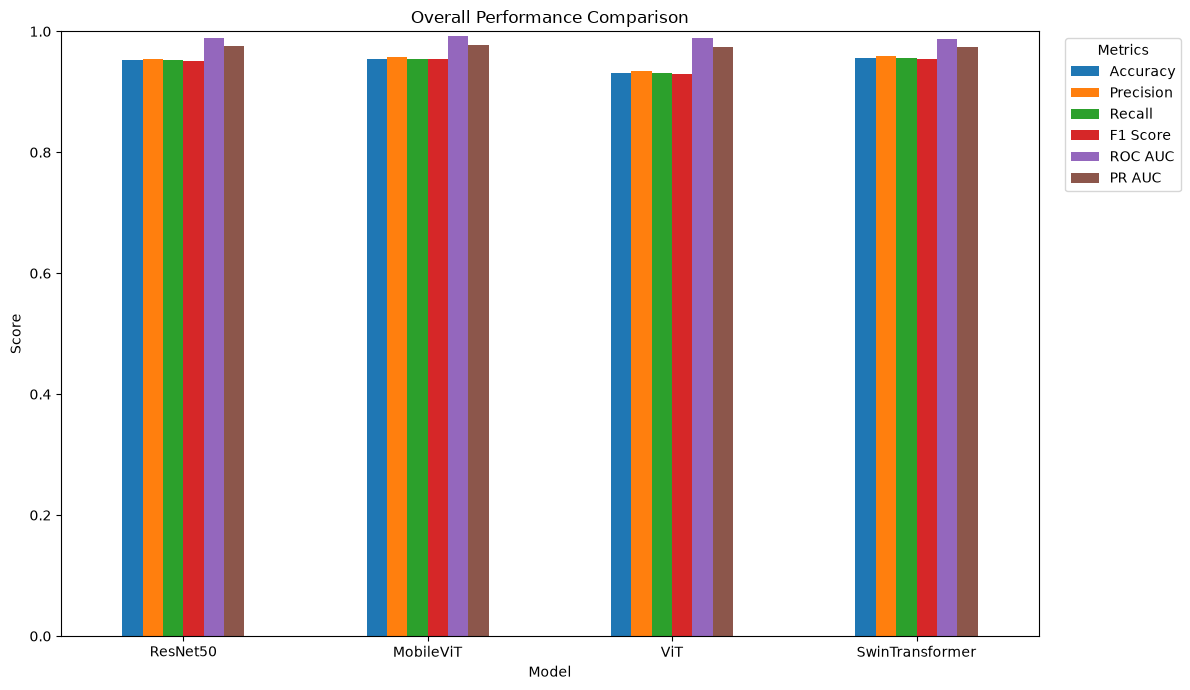

Performance comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\overall_model_performance_comparison.png


In [128]:
# Block 124 - Overall Performance Comparison

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC",
    "PR AUC"
]

comparison_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Overall Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

performance_plot_path = (
    OUTPUT_DIR / "overall_model_performance_comparison.png"
)

plt.savefig(
    performance_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Performance comparison saved to:")
print(performance_plot_path)

In [129]:
# Block 125 - Best Model Identification

best_model_row = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print("=" * 60)
print("BEST PERFORMING MODEL")
print("=" * 60)

print(f"Model     : {best_model_row['Model']}")
print(f"Accuracy  : {best_model_row['Accuracy']:.4f}")
print(f"Precision : {best_model_row['Precision']:.4f}")
print(f"Recall    : {best_model_row['Recall']:.4f}")
print(f"F1 Score  : {best_model_row['F1 Score']:.4f}")
print(f"ROC AUC   : {best_model_row['ROC AUC']:.4f}")
print(f"PR AUC    : {best_model_row['PR AUC']:.4f}")

BEST PERFORMING MODEL
Model     : SwinTransformer
Accuracy  : 0.9556
Precision : 0.9587
Recall    : 0.9556
F1 Score  : 0.9546
ROC AUC   : 0.9870
PR AUC    : 0.9746


In [130]:
# Block 126 - Final Project Output Summary

print("=" * 70)
print("EXPLAINABLE AI FOR BRAIN TUMOR DETECTION")
print("=" * 70)

print("\nModels trained and evaluated:")
for model_name in MODEL_CREATORS.keys():
    print(f"  ✓ {model_name}")

print("\nSaved model files:")
for model_name in MODEL_CREATORS.keys():
    model_path = MODEL_DIR / f"{model_name}.pth"
    print(f"  ✓ {model_path}")

print("\nGenerated analysis:")
print("  ✓ Confusion matrices")
print("  ✓ Classification reports")
print("  ✓ ROC curves")
print("  ✓ Precision-Recall curves")
print("  ✓ Model comparison")
print("  ✓ Grad-CAM explanations")
print("  ✓ Single-image prediction")

print("\nProject outputs are stored in:")
print(OUTPUT_DIR)

print("\n" + "=" * 70)
print("PROJECT PIPELINE COMPLETED")
print("=" * 70)

EXPLAINABLE AI FOR BRAIN TUMOR DETECTION

Models trained and evaluated:
  ✓ ResNet50
  ✓ MobileViT
  ✓ ViT
  ✓ SwinTransformer

Saved model files:
  ✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ResNet50.pth
  ✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\models\MobileViT.pth
  ✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\models\ViT.pth
  ✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\models\SwinTransformer.pth

Generated analysis:
  ✓ Confusion matrices
  ✓ Classification reports
  ✓ ROC curves
  ✓ Precision-Recall curves
  ✓ Model comparison
  ✓ Grad-CAM explanations
  ✓ Single-image prediction

Project outputs are stored in:
c:\Users\Apurv\Desktop\Dataset_29\outputs

PROJECT PIPELINE COMPLETED


In [131]:
# Block 127: Ensemble model loader

def load_trained_model(model_name):
    model = MODEL_CREATORS[model_name](NUM_CLASSES)
    
    model_path = MODEL_DIR / f"{model_name}.pth"
    
    checkpoint = torch.load(
        model_path,
        map_location=DEVICE
    )
    
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
    else:
        model.load_state_dict(checkpoint)
    
    model = model.to(DEVICE)
    model.eval()
    
    print(f"✓ Loaded {model_name}")
    
    return model

In [132]:
# Block 128: Generate predictions from all models

ensemble_model_names = [
    "ResNet50",
    "MobileViT",
    "ViT",
    "SwinTransformer"
]

ensemble_probabilities = {}
ensemble_labels = {}

for model_name in ensemble_model_names:
    
    model = load_trained_model(model_name)
    
    y_true, y_pred, y_prob = get_predictions(
        model,
        test_loader
    )
    
    ensemble_probabilities[model_name] = y_prob
    ensemble_labels[model_name] = y_true
    
    del model
    torch.cuda.empty_cache()
    
    print(f"✓ Predictions collected for {model_name}")

✓ Loaded ResNet50


✓ Predictions collected for ResNet50
✓ Loaded MobileViT


✓ Predictions collected for MobileViT
✓ Loaded ViT


✓ Predictions collected for ViT
✓ Loaded SwinTransformer


✓ Predictions collected for SwinTransformer


In [133]:
# Block 129: Verify prediction alignment

reference_labels = ensemble_labels["ResNet50"]

for model_name in ensemble_model_names:
    assert np.array_equal(
        reference_labels,
        ensemble_labels[model_name]
    ), f"Label mismatch found in {model_name}"

print("✓ All models use the same test-set labels.")

y_true_ensemble = reference_labels

# Shape:
# Number of models × Number of samples × Number of classes
all_probabilities = np.stack(
    [ensemble_probabilities[name] for name in ensemble_model_names],
    axis=0
)

print("Probability array shape:", all_probabilities.shape)

✓ All models use the same test-set labels.
Probability array shape: (4, 1600, 4)


In [134]:
# Block 130: Hard voting ensemble

individual_predictions = np.argmax(
    all_probabilities,
    axis=2
)

hard_vote_predictions = []

for sample_idx in range(individual_predictions.shape[1]):
    
    votes = individual_predictions[:, sample_idx]
    
    vote_count = np.bincount(
        votes,
        minlength=NUM_CLASSES
    )
    
    majority_class = np.argmax(vote_count)
    
    hard_vote_predictions.append(majority_class)

hard_vote_predictions = np.array(
    hard_vote_predictions
)

print("✓ Hard voting predictions generated.")

✓ Hard voting predictions generated.


In [135]:
# Block 131: Hard voting metrics

hard_accuracy = accuracy_score(
    y_true_ensemble,
    hard_vote_predictions
)

hard_precision = precision_score(
    y_true_ensemble,
    hard_vote_predictions,
    average="macro",
    zero_division=0
)

hard_recall = recall_score(
    y_true_ensemble,
    hard_vote_predictions,
    average="macro",
    zero_division=0
)

hard_f1 = f1_score(
    y_true_ensemble,
    hard_vote_predictions,
    average="macro",
    zero_division=0
)

hard_metrics = {
    "Accuracy": hard_accuracy,
    "Precision": hard_precision,
    "Recall": hard_recall,
    "F1 Score": hard_f1
}

print("\nHard Voting Results")
print("=" * 40)

for metric, value in hard_metrics.items():
    print(f"{metric}: {value:.4f}")


Hard Voting Results
Accuracy: 0.9575
Precision: 0.9605
Recall: 0.9575
F1 Score: 0.9566


In [136]:
# Block 132: Soft voting ensemble

soft_vote_probabilities = np.mean(
    all_probabilities,
    axis=0
)

soft_vote_predictions = np.argmax(
    soft_vote_probabilities,
    axis=1
)

print("✓ Soft voting predictions generated.")
print(
    "Soft probability shape:",
    soft_vote_probabilities.shape
)

✓ Soft voting predictions generated.
Soft probability shape: (1600, 4)


In [137]:
# Block 133: Soft voting metrics

soft_metrics = calculate_metrics(
    y_true_ensemble,
    soft_vote_predictions,
    soft_vote_probabilities
)

print("\nSoft Voting Results")
print("=" * 40)

for metric, value in soft_metrics.items():
    print(f"{metric}: {value:.4f}")


Soft Voting Results
Accuracy: 0.9569
Precision: 0.9601
Recall: 0.9569
F1 Score: 0.9558
ROC AUC: 0.9933
PR AUC: 0.9850


In [138]:
# Block 134: Complete model comparison

ensemble_comparison = model_comparison.copy()

hard_row = {
    "Model": "Hard Voting Ensemble",
    "Accuracy": hard_metrics["Accuracy"],
    "Precision": hard_metrics["Precision"],
    "Recall": hard_metrics["Recall"],
    "F1 Score": hard_metrics["F1 Score"],
    "ROC AUC": np.nan,
    "PR AUC": np.nan
}

soft_row = {
    "Model": "Soft Voting Ensemble",
    "Accuracy": soft_metrics["Accuracy"],
    "Precision": soft_metrics["Precision"],
    "Recall": soft_metrics["Recall"],
    "F1 Score": soft_metrics["F1 Score"],
    "ROC AUC": soft_metrics["ROC AUC"],
    "PR AUC": soft_metrics["PR AUC"]
}

ensemble_comparison = pd.concat(
    [
        ensemble_comparison,
        pd.DataFrame([hard_row, soft_row])
    ],
    ignore_index=True
)

display(
    ensemble_comparison.style.format(
        {
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1 Score": "{:.4f}",
            "ROC AUC": "{:.4f}",
            "PR AUC": "{:.4f}"
        }
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,ResNet50,0.9519,0.9550,0.9519,0.9508,0.9897,0.9754
1,MobileViT,0.9550,0.9583,0.9550,0.9541,0.9926,0.9779
2,ViT,0.9312,0.9350,0.9312,0.9293,0.9882,0.9738
3,SwinTransformer,0.9556,0.9587,0.9556,0.9546,0.9870,0.9746
4,Hard Voting Ensemble,0.9575,0.9605,0.9575,0.9566,nan,nan
5,Soft Voting Ensemble,0.9569,0.9601,0.9569,0.9558,0.9933,0.9850


In [139]:
# Block 137: Prepare ROC data for soft-voting ensemble

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

y_true_binary_ensemble = label_binarize(
    y_true_ensemble,
    classes=np.arange(NUM_CLASSES)
)

soft_ensemble_fpr = {}
soft_ensemble_tpr = {}
soft_ensemble_auc = {}

for i, class_name in enumerate(CLASS_NAMES):
    soft_ensemble_fpr[i], soft_ensemble_tpr[i], _ = roc_curve(
        y_true_binary_ensemble[:, i],
        soft_vote_probabilities[:, i]
    )
    
    soft_ensemble_auc[i] = auc(
        soft_ensemble_fpr[i],
        soft_ensemble_tpr[i]
    )

print("✓ Soft ensemble ROC data prepared.")

✓ Soft ensemble ROC data prepared.


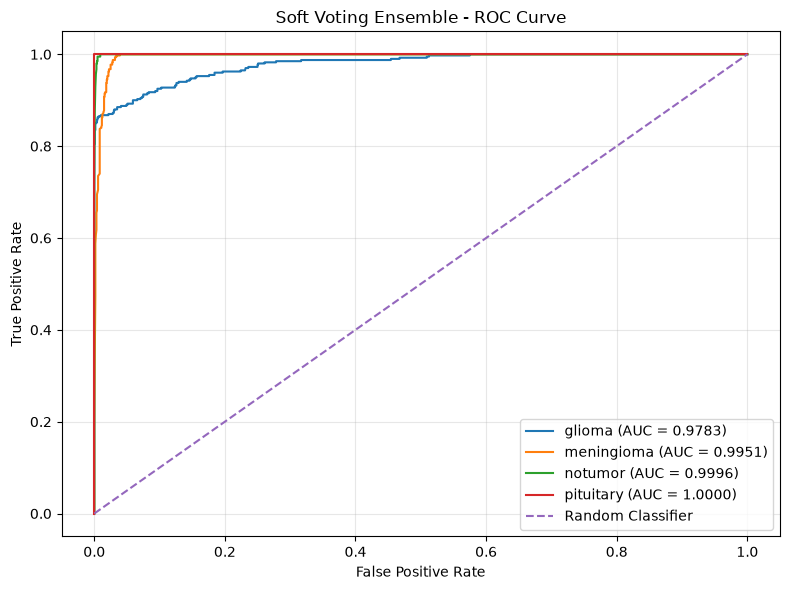

✓ Saved to: c:\Users\Apurv\Desktop\Dataset_29\outputs\roc_curves\Soft_Voting_Ensemble_ROC.png


In [140]:
# Block 138: Soft-voting ensemble ROC curve

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(CLASS_NAMES):
    plt.plot(
        soft_ensemble_fpr[i],
        soft_ensemble_tpr[i],
        label=f"{class_name} (AUC = {soft_ensemble_auc[i]:.4f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Soft Voting Ensemble - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

ensemble_roc_path = (
    ROC_DIR / "Soft_Voting_Ensemble_ROC.png"
)

plt.savefig(
    ensemble_roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"✓ Saved to: {ensemble_roc_path}")

In [141]:
# Block 139: Prepare Precision-Recall data

from sklearn.metrics import precision_recall_curve, average_precision_score

soft_ensemble_precision = {}
soft_ensemble_recall = {}
soft_ensemble_pr_auc = {}

for i, class_name in enumerate(CLASS_NAMES):
    
    precision, recall, _ = precision_recall_curve(
        y_true_binary_ensemble[:, i],
        soft_vote_probabilities[:, i]
    )
    
    soft_ensemble_precision[i] = precision
    soft_ensemble_recall[i] = recall
    
    soft_ensemble_pr_auc[i] = average_precision_score(
        y_true_binary_ensemble[:, i],
        soft_vote_probabilities[:, i]
    )

print("✓ Soft ensemble PR data prepared.")

✓ Soft ensemble PR data prepared.


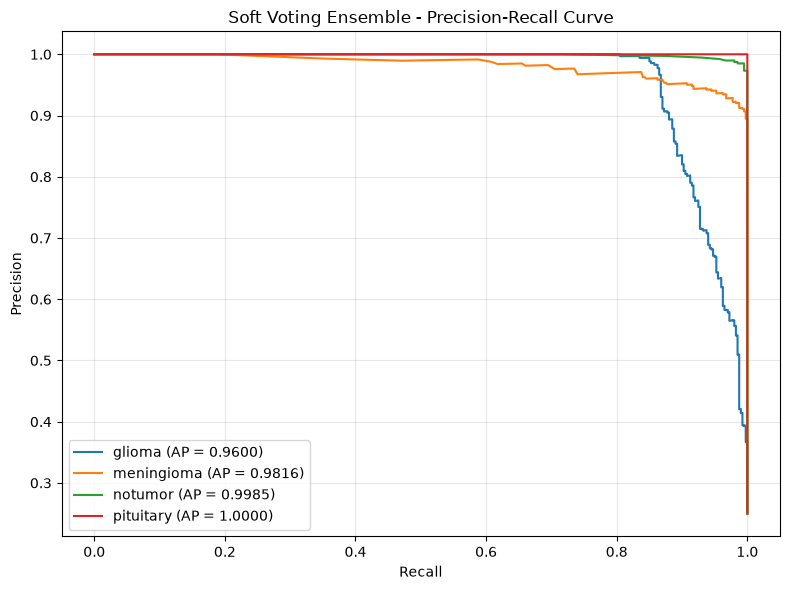

✓ Saved to: c:\Users\Apurv\Desktop\Dataset_29\outputs\precision_recall\Soft_Voting_Ensemble_PR.png


In [142]:
# Block 140: Soft-voting ensemble Precision-Recall curve

plt.figure(figsize=(8, 6))

for i, class_name in enumerate(CLASS_NAMES):
    plt.plot(
        soft_ensemble_recall[i],
        soft_ensemble_precision[i],
        label=f"{class_name} (AP = {soft_ensemble_pr_auc[i]:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Soft Voting Ensemble - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

ensemble_pr_path = (
    PR_DIR / "Soft_Voting_Ensemble_PR.png"
)

plt.savefig(
    ensemble_pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"✓ Saved to: {ensemble_pr_path}")

In [143]:
# Block 141: Soft ensemble classification report

from sklearn.metrics import classification_report

soft_classification_report = classification_report(
    y_true_ensemble,
    soft_vote_predictions,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

soft_report_df = pd.DataFrame(
    soft_classification_report
).transpose()

display(
    soft_report_df.style.format(
        "{:.4f}"
    )
)

,precision,recall,f1-score,support
glioma,0.9970,0.8300,0.9059,400.0000
meningioma,0.9068,0.9975,0.9500,400.0000
notumor,0.9368,1.0000,0.9674,400.0000
pituitary,1.0000,1.0000,1.0000,400.0000
accuracy,0.9569,0.9569,0.9569,0.9569
macro avg,0.9601,0.9569,0.9558,1600.0000
weighted avg,0.9601,0.9569,0.9558,1600.0000


In [144]:
# Block 142: Per-class performance table

per_class_metrics = soft_report_df.loc[
    CLASS_NAMES,
    ["precision", "recall", "f1-score", "support"]
].copy()

per_class_metrics = per_class_metrics.rename(
    columns={
        "precision": "Precision",
        "recall": "Recall",
        "f1-score": "F1 Score",
        "support": "Support"
    }
)

display(
    per_class_metrics.style.format(
        {
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1 Score": "{:.4f}",
            "Support": "{:.0f}"
        }
    )
)

,Precision,Recall,F1 Score,Support
glioma,0.9970,0.8300,0.9059,400
meningioma,0.9068,0.9975,0.9500,400
notumor,0.9368,1.0000,0.9674,400
pituitary,1.0000,1.0000,1.0000,400


In [145]:
# Block 143: Per-class ROC-AUC

per_class_roc_auc = []

for i, class_name in enumerate(CLASS_NAMES):
    
    class_auc = roc_auc_score(
        y_true_binary_ensemble[:, i],
        soft_vote_probabilities[:, i]
    )
    
    per_class_roc_auc.append({
        "Class": class_name,
        "ROC AUC": class_auc
    })

per_class_roc_df = pd.DataFrame(
    per_class_roc_auc
)

display(
    per_class_roc_df.style.format(
        {"ROC AUC": "{:.4f}"}
    )
)

,Class,ROC AUC
0,glioma,0.9783
1,meningioma,0.9951
2,notumor,0.9996
3,pituitary,1.0000


In [146]:
# Block 144: Save per-class ensemble results

per_class_metrics_path = (
    OUTPUT_DIR / "soft_ensemble_per_class_metrics.csv"
)

per_class_roc_path = (
    OUTPUT_DIR / "soft_ensemble_per_class_roc_auc.csv"
)

per_class_metrics.to_csv(
    per_class_metrics_path
)

per_class_roc_df.to_csv(
    per_class_roc_path,
    index=False
)

print("✓ Per-class metrics saved.")
print(f"✓ {per_class_metrics_path}")
print(f"✓ {per_class_roc_path}")

✓ Per-class metrics saved.
✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\soft_ensemble_per_class_metrics.csv
✓ c:\Users\Apurv\Desktop\Dataset_29\outputs\soft_ensemble_per_class_roc_auc.csv


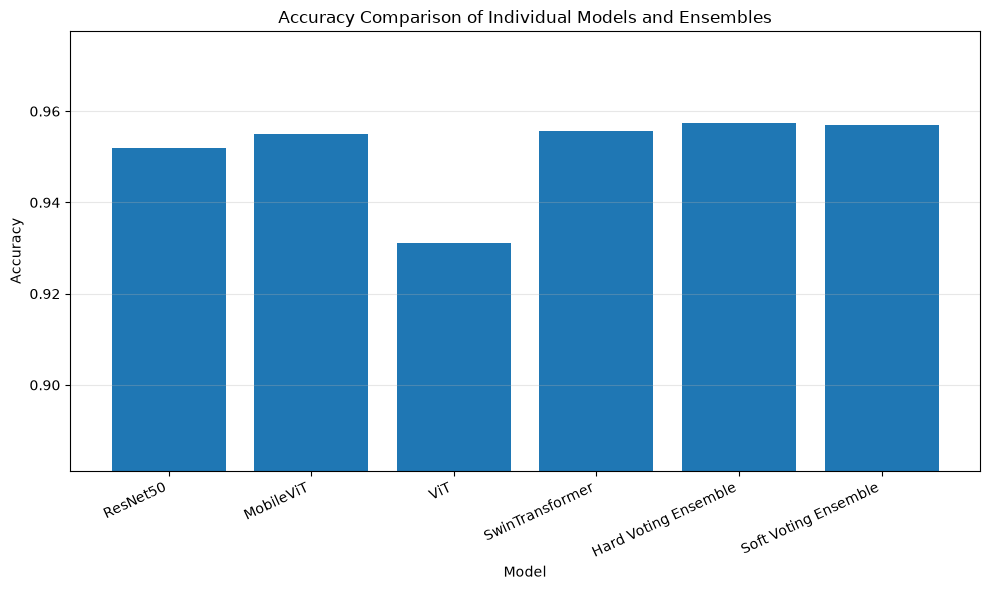

✓ Saved to: c:\Users\Apurv\Desktop\Dataset_29\outputs\accuracy_model_comparison.png


In [147]:
# Block 145: Accuracy comparison

plt.figure(figsize=(10, 6))

comparison_plot = ensemble_comparison.copy()

plt.bar(
    comparison_plot["Model"],
    comparison_plot["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Accuracy Comparison of Individual Models and Ensembles")

plt.ylim(
    max(0, comparison_plot["Accuracy"].min() - 0.05),
    min(1.0, comparison_plot["Accuracy"].max() + 0.02)
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

accuracy_plot_path = (
    OUTPUT_DIR / "accuracy_model_comparison.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"✓ Saved to: {accuracy_plot_path}")

In [148]:
# Block 146: Final performance comparison

final_metrics = ensemble_comparison[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC",
        "PR AUC"
    ]
].copy()

display(
    final_metrics.style.format(
        {
            "Accuracy": "{:.4f}",
            "Precision": "{:.4f}",
            "Recall": "{:.4f}",
            "F1 Score": "{:.4f}",
            "ROC AUC": "{:.4f}",
            "PR AUC": "{:.4f}"
        }
    )
)

final_comparison_path = (
    OUTPUT_DIR / "final_model_comparison.csv"
)

final_metrics.to_csv(
    final_comparison_path,
    index=False
)

print("\n" + "=" * 60)
print("FINAL MODEL EVALUATION COMPLETED")
print("=" * 60)

best_accuracy_row = final_metrics.loc[
    final_metrics["Accuracy"].idxmax()
]

print(
    f"\nBest model by accuracy: "
    f"{best_accuracy_row['Model']}"
)

print(
    f"Accuracy: "
    f"{best_accuracy_row['Accuracy']:.4f}"
)

print(f"\n✓ Final comparison saved to:")
print(final_comparison_path)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,PR AUC
0,ResNet50,0.9519,0.9550,0.9519,0.9508,0.9897,0.9754
1,MobileViT,0.9550,0.9583,0.9550,0.9541,0.9926,0.9779
2,ViT,0.9312,0.9350,0.9312,0.9293,0.9882,0.9738
3,SwinTransformer,0.9556,0.9587,0.9556,0.9546,0.9870,0.9746
4,Hard Voting Ensemble,0.9575,0.9605,0.9575,0.9566,nan,nan
5,Soft Voting Ensemble,0.9569,0.9601,0.9569,0.9558,0.9933,0.9850



FINAL MODEL EVALUATION COMPLETED

Best model by accuracy: Hard Voting Ensemble
Accuracy: 0.9575

✓ Final comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\final_model_comparison.csv


In [149]:
# Block 147: Check Grad-CAM outputs

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

gradcam_files = {}

for model_name in ensemble_model_names:
    gradcam_path = GRADCAM_DIR / f"{model_name}_gradcam.png"
    gradcam_files[model_name] = gradcam_path
    
    if gradcam_path.exists():
        print(f"✓ {model_name}: {gradcam_path.name}")
    else:
        print(f"✗ Missing: {model_name}")

print("\nGrad-CAM output directory:")
print(GRADCAM_DIR)

✓ ResNet50: ResNet50_gradcam.png
✓ MobileViT: MobileViT_gradcam.png
✓ ViT: ViT_gradcam.png
✓ SwinTransformer: SwinTransformer_gradcam.png

Grad-CAM output directory:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam


In [150]:
# Block 148: Select a test MRI image

sample_index = 0

sample_path, sample_label = test_dataset.samples[sample_index]

print("Selected MRI:")
print(sample_path)

print("\nGround Truth:")
print(CLASS_NAMES[sample_label])

Selected MRI:
c:\Users\Apurv\Desktop\Dataset_29\Testing\glioma\Te-gl_1.jpg

Ground Truth:
glioma


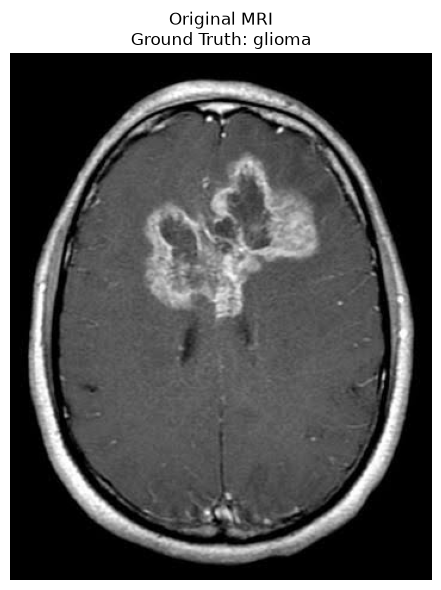

In [151]:
# Block 149: Display original MRI

original_image = Image.open(sample_path).convert("RGB")

plt.figure(figsize=(6, 6))

plt.imshow(original_image)
plt.title(
    f"Original MRI\nGround Truth: {CLASS_NAMES[sample_label]}"
)
plt.axis("off")

plt.tight_layout()
plt.show()

In [152]:
# Block 150: Individual model predictions for selected MRI

single_image_tensor = test_transform(
    original_image
).unsqueeze(0).to(DEVICE)

single_model_results = {}

for model_name in ensemble_model_names:
    
    model = load_trained_model(model_name)
    
    with torch.no_grad():
        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(single_image_tensor)
    
    probabilities = torch.softmax(
        outputs,
        dim=1
    )[0].float().cpu().numpy()
    
    prediction = int(np.argmax(probabilities))
    
    single_model_results[model_name] = {
        "prediction": prediction,
        "probabilities": probabilities
    }
    
    print(
        f"{model_name}: "
        f"{CLASS_NAMES[prediction]} "
        f"({probabilities[prediction] * 100:.2f}%)"
    )
    
    del model, outputs
    torch.cuda.empty_cache()

✓ Loaded ResNet50
ResNet50: glioma (66.75%)
✓ Loaded MobileViT
MobileViT: glioma (49.34%)
✓ Loaded ViT
ViT: meningioma (98.05%)
✓ Loaded SwinTransformer
SwinTransformer: glioma (98.39%)


In [153]:
# Block 151: Soft ensemble prediction for selected MRI

single_model_probabilities = np.stack(
    [
        single_model_results[name]["probabilities"]
        for name in ensemble_model_names
    ],
    axis=0
)

single_soft_probabilities = np.mean(
    single_model_probabilities,
    axis=0
)

single_soft_prediction = int(
    np.argmax(single_soft_probabilities)
)

print("=" * 50)
print("SOFT VOTING ENSEMBLE")
print("=" * 50)

print(
    f"Prediction: "
    f"{CLASS_NAMES[single_soft_prediction]}"
)

print(
    f"Confidence: "
    f"{single_soft_probabilities[single_soft_prediction] * 100:.2f}%"
)

print("\nClass probabilities:")

for class_name, probability in zip(
    CLASS_NAMES,
    single_soft_probabilities
):
    print(
        f"{class_name}: "
        f"{probability * 100:.2f}%"
    )

SOFT VOTING ENSEMBLE
Prediction: glioma
Confidence: 53.73%

Class probabilities:
glioma: 53.73%
meningioma: 26.80%
notumor: 13.44%
pituitary: 6.02%


In [154]:
# Block 152: Prediction summary table

prediction_rows = []

for model_name in ensemble_model_names:
    
    result = single_model_results[model_name]
    prediction = result["prediction"]
    confidence = result["probabilities"][prediction]
    
    prediction_rows.append({
        "Model": model_name,
        "Prediction": CLASS_NAMES[prediction],
        "Confidence": confidence
    })

prediction_rows.append({
    "Model": "Soft Voting Ensemble",
    "Prediction": CLASS_NAMES[single_soft_prediction],
    "Confidence": single_soft_probabilities[single_soft_prediction]
})

prediction_summary_df = pd.DataFrame(
    prediction_rows
)

prediction_summary_df["Confidence"] = (
    prediction_summary_df["Confidence"] * 100
)

display(
    prediction_summary_df.style.format(
        {
            "Confidence": "{:.2f}%"
        }
    )
)

,Model,Prediction,Confidence
0,ResNet50,glioma,66.75%
1,MobileViT,glioma,49.34%
2,ViT,meningioma,98.05%
3,SwinTransformer,glioma,98.39%
4,Soft Voting Ensemble,glioma,53.73%


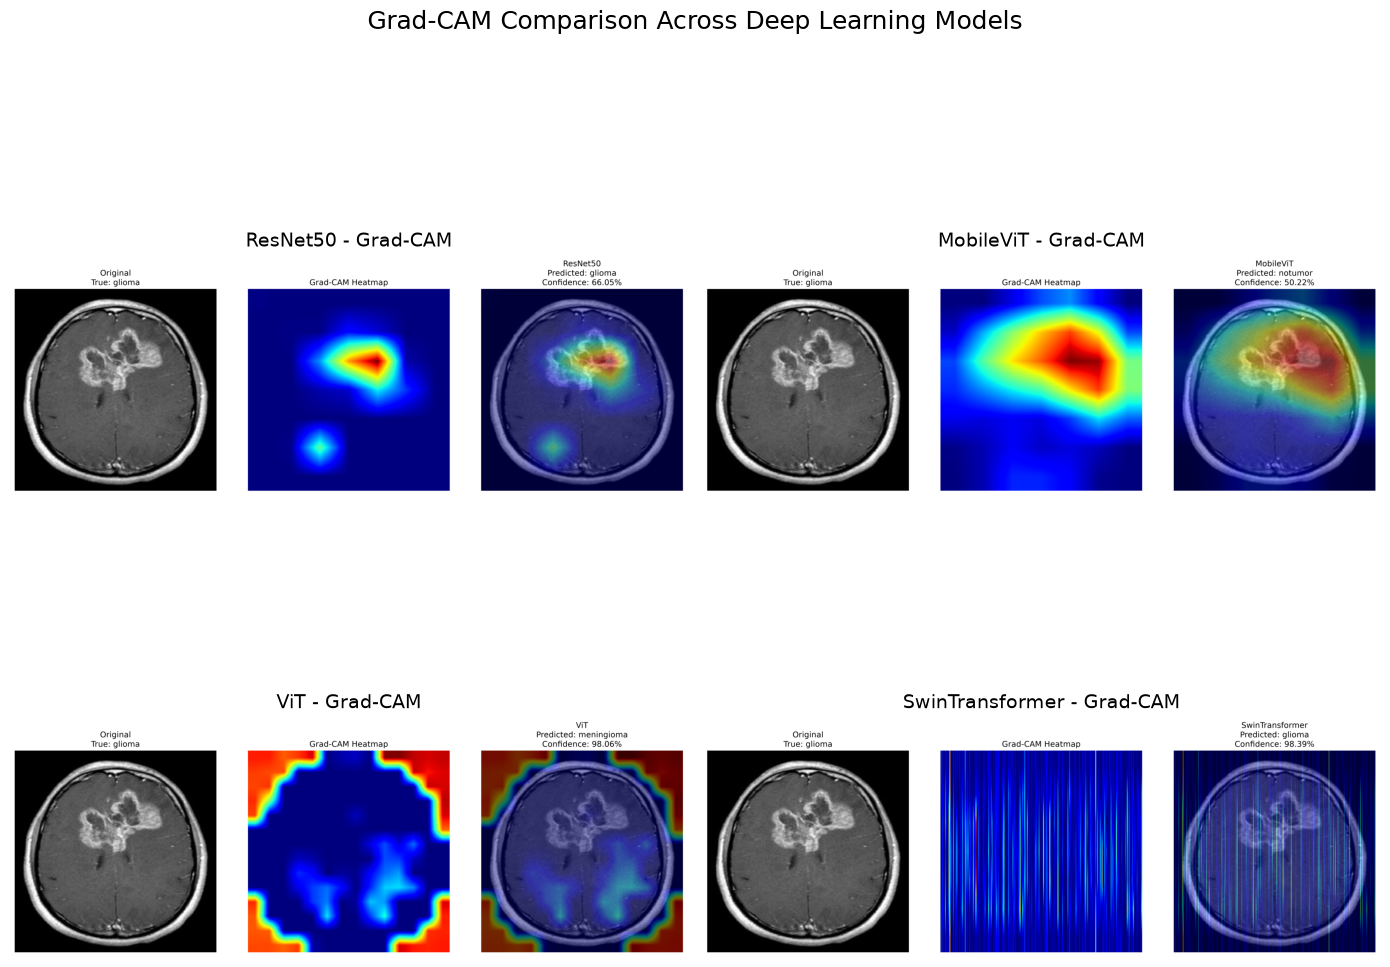

In [155]:
# Block 153: Display Grad-CAM explanations

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12)
)

axes = axes.flatten()

for ax, model_name in zip(
    axes,
    ensemble_model_names
):
    
    gradcam_path = gradcam_files[model_name]
    
    if gradcam_path.exists():
        gradcam_image = Image.open(
            gradcam_path
        ).convert("RGB")
        
        ax.imshow(gradcam_image)
        ax.set_title(
            f"{model_name} - Grad-CAM",
            fontsize=14
        )
    else:
        ax.text(
            0.5,
            0.5,
            "Grad-CAM not available",
            ha="center",
            va="center"
        )
    
    ax.axis("off")

plt.suptitle(
    "Grad-CAM Comparison Across Deep Learning Models",
    fontsize=18
)

plt.tight_layout()
plt.show()

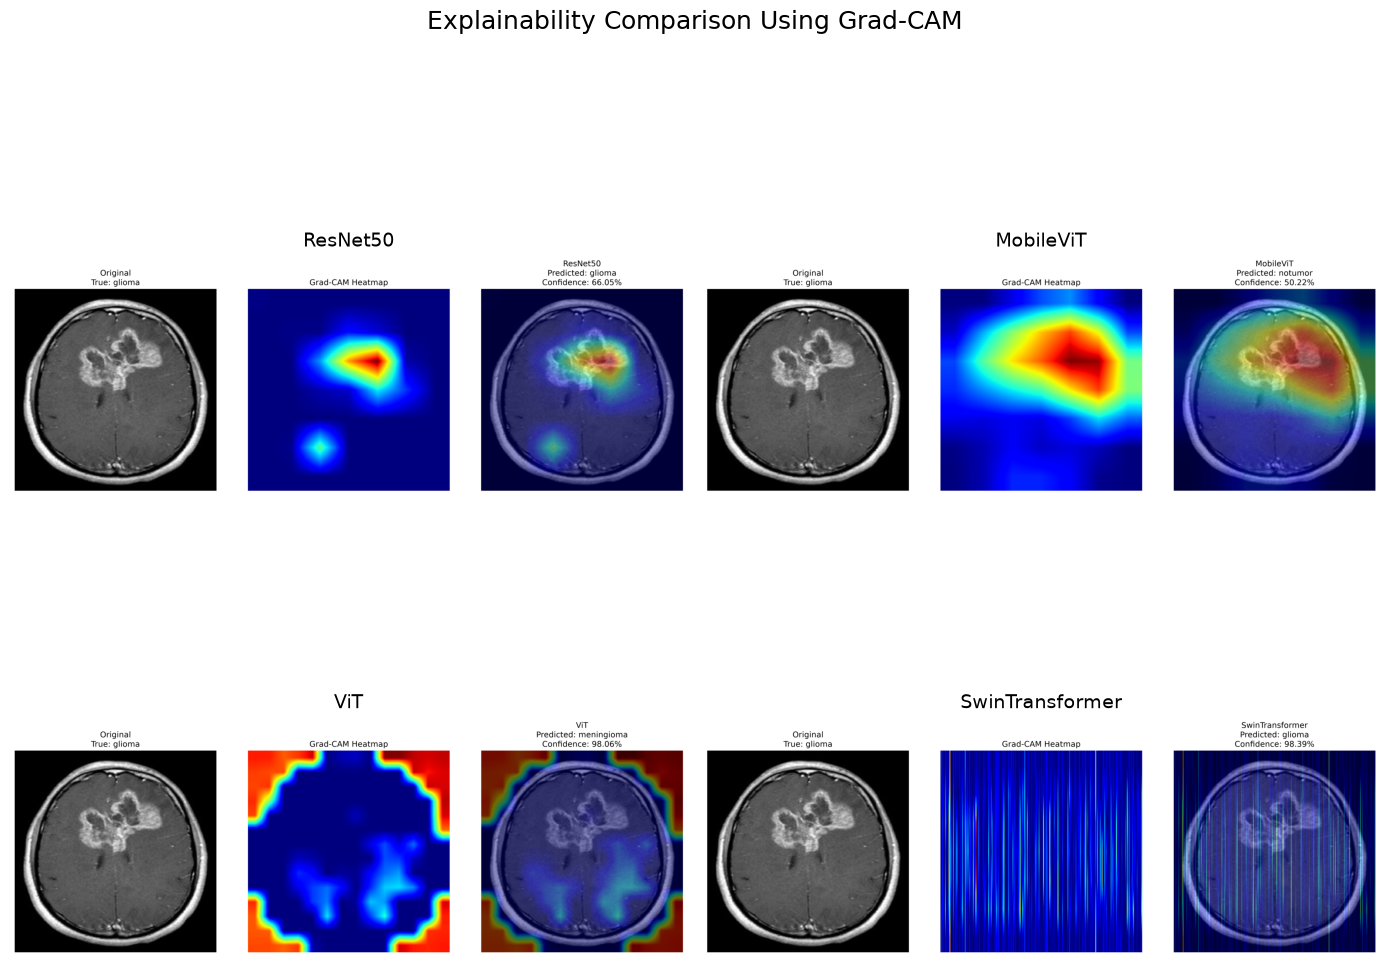

✓ XAI comparison saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\GradCAM_Model_Comparison.png


In [156]:
# Block 154: Save combined Grad-CAM figure

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 12)
)

axes = axes.flatten()

for ax, model_name in zip(
    axes,
    ensemble_model_names
):
    
    gradcam_path = gradcam_files[model_name]
    
    if gradcam_path.exists():
        gradcam_image = Image.open(
            gradcam_path
        ).convert("RGB")
        
        ax.imshow(gradcam_image)
        ax.set_title(
            model_name,
            fontsize=14
        )
    
    ax.axis("off")

plt.suptitle(
    "Explainability Comparison Using Grad-CAM",
    fontsize=18
)

plt.tight_layout()

xai_comparison_path = (
    GRADCAM_DIR / "GradCAM_Model_Comparison.png"
)

plt.savefig(
    xai_comparison_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✓ XAI comparison saved to:\n"
    f"{xai_comparison_path}"
)

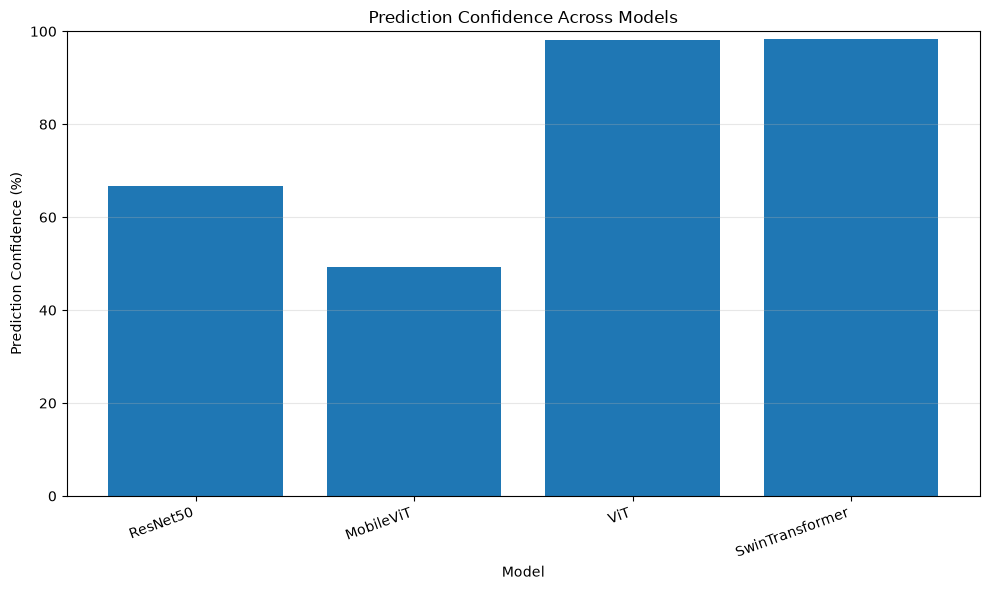

✓ Saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\Model_Confidence_Comparison.png


In [157]:
# Block 155: Model confidence comparison

plt.figure(figsize=(10, 6))

model_names_plot = list(
    single_model_results.keys()
)

confidence_values = [
    single_model_results[name]["probabilities"][
        single_model_results[name]["prediction"]
    ] * 100
    for name in model_names_plot
]

plt.bar(
    model_names_plot,
    confidence_values
)

plt.ylabel("Prediction Confidence (%)")
plt.xlabel("Model")
plt.title(
    "Prediction Confidence Across Models"
)

plt.ylim(0, 100)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

confidence_plot_path = (
    GRADCAM_DIR / "Model_Confidence_Comparison.png"
)

plt.savefig(
    confidence_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"✓ Saved to:\n"
    f"{confidence_plot_path}"
)

In [158]:
# Block 156: Final XAI case-study summary

xai_summary = {
    "MRI Path": str(sample_path),
    "Ground Truth": CLASS_NAMES[sample_label],
    "ResNet50 Prediction": CLASS_NAMES[
        single_model_results["ResNet50"]["prediction"]
    ],
    "MobileViT Prediction": CLASS_NAMES[
        single_model_results["MobileViT"]["prediction"]
    ],
    "ViT Prediction": CLASS_NAMES[
        single_model_results["ViT"]["prediction"]
    ],
    "SwinTransformer Prediction": CLASS_NAMES[
        single_model_results["SwinTransformer"]["prediction"]
    ],
    "Soft Ensemble Prediction": CLASS_NAMES[
        single_soft_prediction
    ],
    "Soft Ensemble Confidence": (
        single_soft_probabilities[
            single_soft_prediction
        ]
    )
}

xai_summary_df = pd.DataFrame(
    [xai_summary]
)

xai_summary_df["Soft Ensemble Confidence"] *= 100

display(
    xai_summary_df.T.rename(
        columns={0: "Result"}
    )
)

xai_summary_path = (
    GRADCAM_DIR / "final_xai_case_study.csv"
)

xai_summary_df.to_csv(
    xai_summary_path,
    index=False
)

print(
    f"\n✓ Final XAI case study saved to:\n"
    f"{xai_summary_path}"
)

,Result
MRI Path,c:\Users\Apurv\Desktop\Dataset_29\Testing\glio...
Ground Truth,glioma
ResNet50 Prediction,glioma
MobileViT Prediction,glioma
ViT Prediction,meningioma
SwinTransformer Prediction,glioma
Soft Ensemble Prediction,glioma
Soft Ensemble Confidence,53.730965



✓ Final XAI case study saved to:
c:\Users\Apurv\Desktop\Dataset_29\outputs\gradcam\final_xai_case_study.csv
